# 7 (v2). External training, climate matching and transfer to Atok

**What this notebook is.** An exploratory feasibility study of transferring crop classifiers trained on external datasets (CropHarvest, Sen4AgriNet, FranceCrops) to Atok. **It is not a validated crop-classification prototype.** The Atok labels are advisor-described rotations without recorded planting dates (the Paoay KML), repeated across 2019-2025, and only 2 carrot, 2 cabbage and 1 potato field are labelled. Every Atok score measures agreement with that assumed calendar on very few independent fields. Section 9 sets out the acceptance criteria a verified pilot would have to meet.

This revision responds to a methodological review of the first version. Its main additions:

- **Baselines:** majority-class and random baselines, plus balanced accuracy, next to every score.
- **Model comparison:** RF and LR compared on the same predictors.
- **Overfitting checks:** a grouped-CV tuning grid, per-crop learning curves at the prototype's 1,000 trees, grouped permutation importance and feature-family ablation.
- **Calibration:** reliability measured, then a calibration fitted on grouped out-of-fold predictions; the abstention threshold is tested on unseen regions; out-of-distribution check; risk-coverage curves and rejection causes.
- **Transfer tests:** leave-one-region-out runs and a train-region × test-region matrix.
- **Controlled climate test:** primary test on external target regions with verified labels (every eligible source set per target, per-target robustness). Atok is an exploratory application only.
- **Comparable transfer scores:** split by number of shared crops, plus one-vs-rest AUC per crop.
- **Local benchmark recast** as a weak-label fitting diagnostic; field-independent validation reported as unavailable.
- **Domain shift:** temporal signatures compared by crop and source.
- **Maps:** an unknown class, the best- and worst-coverage years, and disagreement maps with pixel counts.

| Section | Objective | Output |
|---|---|---|
| 1. Data inventory and profiling | Obj 1 | Inventory, independent sample units, region × crop coverage, calendar coverage, climate distances, domain shift |
| 2. Preprocessing QC | Obj 2 | Pointer to notebooks 01-05 and their audits |
| 3. Dataset specification | Obj 3a | Spec table, unit-by-unit exclusion funnel, record-level CropHarvest exclusions |
| 4. External models and diagnostics | Obj 3b | Same-predictor comparison, tuning, learning curves, importance, calibration, leave-one-region-out |
| 5. Climate-matching experiment | Obj 3b | All eligible region sets: climate distance vs Atok agreement, size-matched control |
| 6. Atok evaluation (provisional labels) | - | Baselines, sample units, clear-data sensitivity, domain shift, failure analysis, exploratory local benchmark |
| 7. Atok maps (exploratory) | Obj 3b | Class maps with an unknown class, two years, disagreement maps |
| 8-9. Limitations, requirements and acceptance criteria | Obj 4 | Evidence-backed limitations, proposed pilot acceptance criteria and current status |

Outputs go to `analysis/transferability/`. This notebook reuses v1's cached tables, locked test split and CV results from `analysis/external/`. Inputs are set in `settings.local.json` (see settings.example.json).

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
from IPython.display import display

from crop_pipeline.transferability import atok as atok_data
from crop_pipeline.transferability import climate, config, experiments, external, maps, models, plots, report
from crop_pipeline.transferability.config import CLASSES, INTERVAL, LR_SHAPE, MIN_CLEAR, OOD_QUANTILE, PROTOTYPE

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
warnings.filterwarnings("ignore", message="Geometry is in a geographic CRS")
pd.set_option("display.precision", 3)
pd.set_option("display.width", 220)

In [2]:
config.chdir_to_repository()
paths = config.load_paths()  # settings.local.json; keys are listed in settings.example.json
config.check_inputs(paths)
OUTPUT, FIGURES = paths.output, paths.figures
print("Output folder:", OUTPUT)

Output folder: /Users/almiravelasquez/workspaces/external-crop-data-classification/analysis/transferability


## Inputs

**External tables.** These are v1's cached CropHarvest and Sen4AgriNet/FranceCrops tables, with the same harmonisation, SAVI and shape features, 10 m parcel linking and locked test split. The split is checked against v1's `test_split.csv` and must match exactly.

**Atok.** This uses the ROI cube cached by notebook 08 or 09 (half-month Cloud Score+ composites, 2019-2026) and the KML polygons. An Atok sample is one pixel in one calendar window: 8 half-months starting at the calendar planting month. It needs at least 6 clear composites; gaps are interpolated linearly.

In [3]:
tables, data = external.load_data(paths)  # v1's cached tables and locked test split
development, test = external.split_partitions(data)
print(f"External rows: {len(data):,}; parcels: {data['partition_group'].nunique()}; "
      f"test parcels: {test['partition_group'].nunique()}")

External rows: 2,653; parcels: 291; test parcels: 58


In [4]:
roi = atok_data.load_grid(paths)  # ROI cube cached by notebook 08/09, with the KML fields on its grid
print(f"Atok cube {roi.cube.shape}, {roi.composites} composites; interior pixels:",
      {name: int(mask.sum()) for name, mask in roi.interiors.items()})

Atok cube (192, 5, 295, 326), 179 composites; interior pixels: {'B1': 312, 'B2': 52, 'Area 2': 442, 'Area 3': 25, 'Area 5': 28}


In [5]:
atok_all, atok, atok_windows = atok_data.labelled_samples(roi)  # provisional labels: atok_data.LABEL_ROWS
print(f"Atok labelled pixel-windows (>= {MIN_CLEAR} clear): {len(atok):,} of {atok_windows['pixel_windows'].sum():,}")

Atok labelled pixel-windows (>= 6 clear): 8,903 of 11,991


In [6]:
atok_units = atok_data.sample_units(atok)
atok_units.to_csv(OUTPUT / "atok_sample_units.csv")
print("Primary sample sizes are the fields and field-seasons; pixel-windows within a field are not independent:")
display(atok_units)

Primary sample sizes are the fields and field-seasons; pixel-windows within a field are not independent:


,independent fields,fields,field-seasons (field x calendar window),field-season-years,pixel-windows (not independent),"verified (dated, field-checked) fields"
carrot,2,"Area 2, B1",2,14,5117,0
cabbage,2,"Area 2, Area 3",4,20,1306,0
potato,1,Area 2,1,7,2480,0


## 1. Data inventory and profiling (Obj 1)

### 1.1 Inventory

There is one row per source and crop. For the external sources, `samples` = `pixels` (one window per pixel); for Atok, `pixels` counts unique pixels and `samples` counts pixel-windows across 2019-2025. `parcels` means parcels for the external sources and KML fields for Atok. Label provenance separates verified labels from published datasets from the advisor-described rotation. B2 (lettuce) and Area 5 (seedbeds) are listed, but the model has no `other_crop` class to use them.

In [7]:
inventory = external.inventory(data, atok, roi.interiors)
inventory.to_csv(OUTPUT / "inventory.csv", index=False)
display(inventory)

,source,crop,years,regions,parcels,pixels,samples,pixels_per_parcel_median,label_provenance,label_detail
0,CropHarvest,cabbage,"2019, 2021",Martinique (FR) 148; Senegal 127; Île-de-Franc...,20,359,359,5.0,verified: published dataset,"survey or declaration label, one season; no wi..."
1,CropHarvest,carrot,2019,Madagascar 123; Réunion (FR) 100; Île-de-Franc...,45,294,294,2.0,verified: published dataset,"survey or declaration label, one season; no wi..."
2,CropHarvest,potato,2019,Île-de-France 205; Réunion (FR) 156; Madagasca...,50,500,500,3.0,verified: published dataset,"survey or declaration label, one season; no wi..."
3,FranceCrops,cabbage,2022,France 500,18,500,500,28.0,verified: published dataset,"French parcel declaration, 2022 season"
4,Sen4AgriNet,carrot,2020,Catalonia (ES) 500,26,500,500,19.5,verified: published dataset,"Catalonia farmer declaration, 2020 season"
5,Sen4AgriNet,potato,2020,Catalonia (ES) 500,132,500,500,4.0,verified: published dataset,"Catalonia farmer declaration, 2020 season"
6,Atok (Paoay KML),cabbage,2019-2025 (calendar repeated),Area 2 442; Area 3 25,2,467,1306,233.5,advisor-described rotation (provisional),"rotation, undated; year-round, no season"
7,Atok (Paoay KML),carrot,2019-2025 (calendar repeated),Area 2 442; B1 312,2,754,5117,377.0,advisor-described rotation (provisional),"rotation, undated"
8,Atok (Paoay KML),potato,2019-2025 (calendar repeated),Area 2 442,1,442,2480,442.0,advisor-described rotation (provisional),"rotation, undated"
9,Atok (Paoay KML),other: lettuce,-,B2,1,52,0,52.0,advisor-described rotation (provisional),not used: no other_crop class


In [8]:
imbalance = external.imbalance(inventory)
imbalance.to_csv(OUTPUT / "imbalance.csv", index=False)
print("Imbalance ratios (largest ÷ smallest class; a source with one crop has ratio 1 and cannot be balanced):")
display(imbalance)

Imbalance ratios (largest ÷ smallest class; a source with one crop has ratio 1 and cannot be balanced):


,source,largest class (samples),smallest class (samples),sample ratio,parcel ratio,crops
0,Atok (Paoay KML),carrot,cabbage,3.918,2.000,3
1,CropHarvest,potato,carrot,1.701,2.500,3
2,FranceCrops,cabbage,cabbage,1.000,1.000,1
3,Sen4AgriNet,carrot,carrot,1.000,5.077,2
4,External pooled,potato,carrot,1.259,4.789,3


### 1.2 Parcel centroids

Each dot is one parcel's mean pixel location. The labels give parcels and pixels per source region. The star is the Atok ROI.

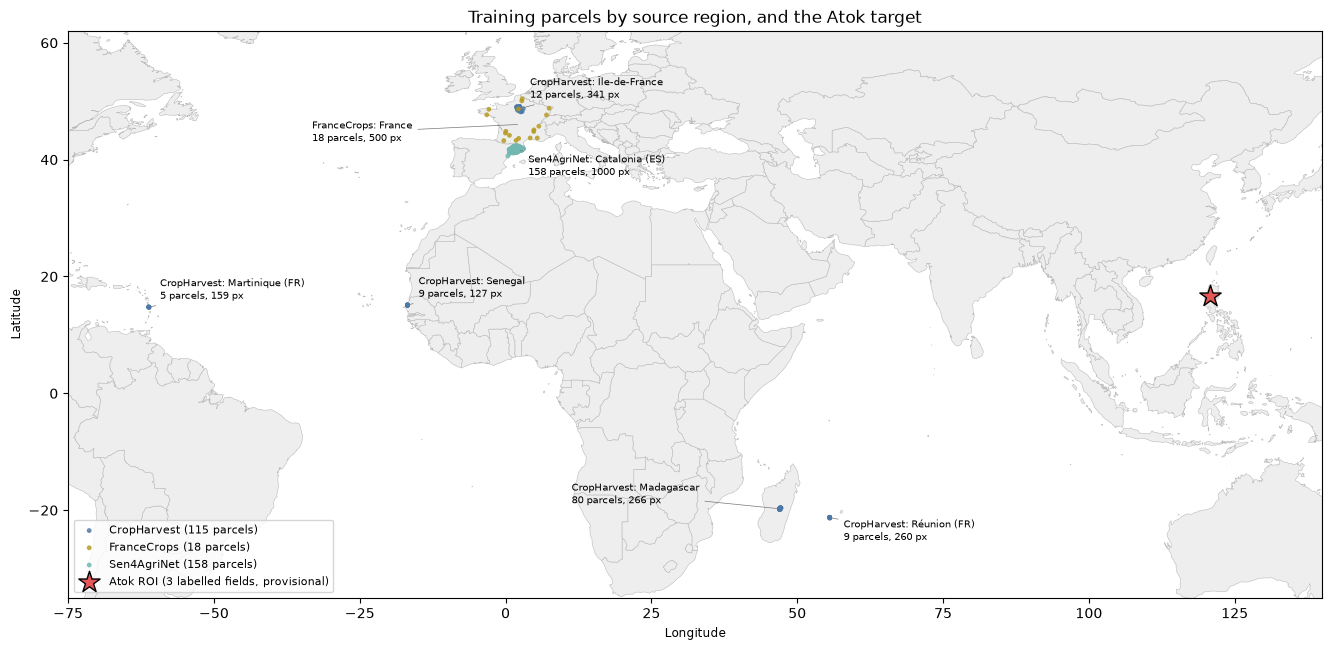

,parcels,pixels
source_region,,
CropHarvest: Madagascar,80,266
CropHarvest: Martinique (FR),5,159
CropHarvest: Réunion (FR),9,260
CropHarvest: Senegal,9,127
CropHarvest: Île-de-France,12,341
FranceCrops: France,18,500
Sen4AgriNet: Catalonia (ES),158,1000


In [9]:
region_counts = external.region_counts(data)
plots.parcel_centroids(data, region_counts, atok, roi, paths.countries_zip, FIGURES)
display(region_counts[["parcels", "pixels"]])

**Region × crop coverage.** Parcel counts per source region and crop, development + test, with Atok's provisional fields underneath. Empty cells are crop-region combinations with no data at all: a model trained on that region has never seen that crop.

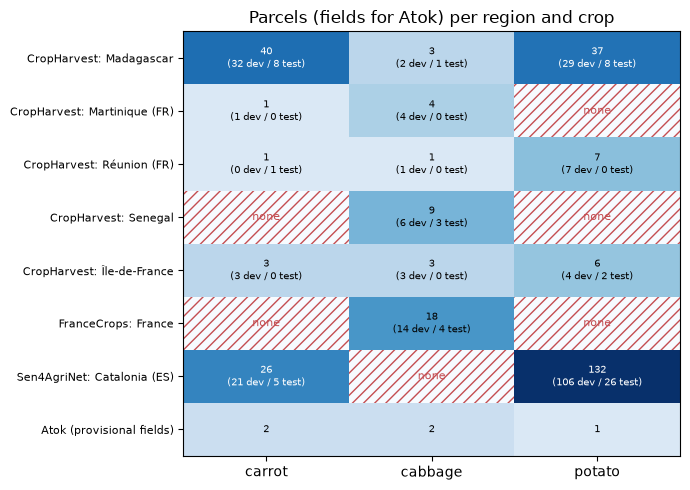

In [10]:
coverage, dev_test = external.region_crop_parcels(data, atok)
coverage.to_csv(OUTPUT / "region_crop_parcels.csv")
plots.region_crop_coverage(coverage, dev_test, FIGURES)

### 1.3 Half-month coverage vs the Atok crop calendar

The top panel shows the share of Atok ROI pixels with a clear composite in each half-month (2019-2025 mean). The rows below show:

- **Atok calendar:** each labelled crop season from the KML.
- **Sen4AgriNet and FranceCrops:** the share of parcels whose 8-half-month window covers each half-month (window starts from notebook 04's onset detection).
- **CropHarvest:** window start dates were not saved. For the JECAM rows (Madagascar, Senegal), the window is approximated as 8 half-months from the recorded planting date. The other CropHarvest regions have no dates, so they cannot be placed on this axis.

Each row is tagged by evidence type. **Assumed** rows come from the undated advisor calendar. **Observed** rows come from onset detection on the imagery. **Approximate** rows come from a recorded planting date plus 4 months. Months are calendar months: Madagascar is in the southern hemisphere, so its seasons are about 6 months out of phase with Atok's, and section 1.4 adds a season-aligned climate distance.

In [11]:
windows = external.external_windows(paths, data)  # notebook 04 windows behind the Sen4AgriNet/FranceCrops table
catalogue = external.cropharvest_catalogue(paths.cropharvest_labels)  # target-crop labels only
ch_rows, ch_match = external.match_cropharvest(data, catalogue)
ch_planting = external.cropharvest_planting(ch_match)
print(f"CropHarvest rows matched to a catalogue label within {external.MATCH_RADIUS_M} m: "
      f"{(ch_match['distance_m'] <= external.MATCH_RADIUS_M).mean():.0%}")

CropHarvest rows matched to a catalogue label within 300 m: 100%


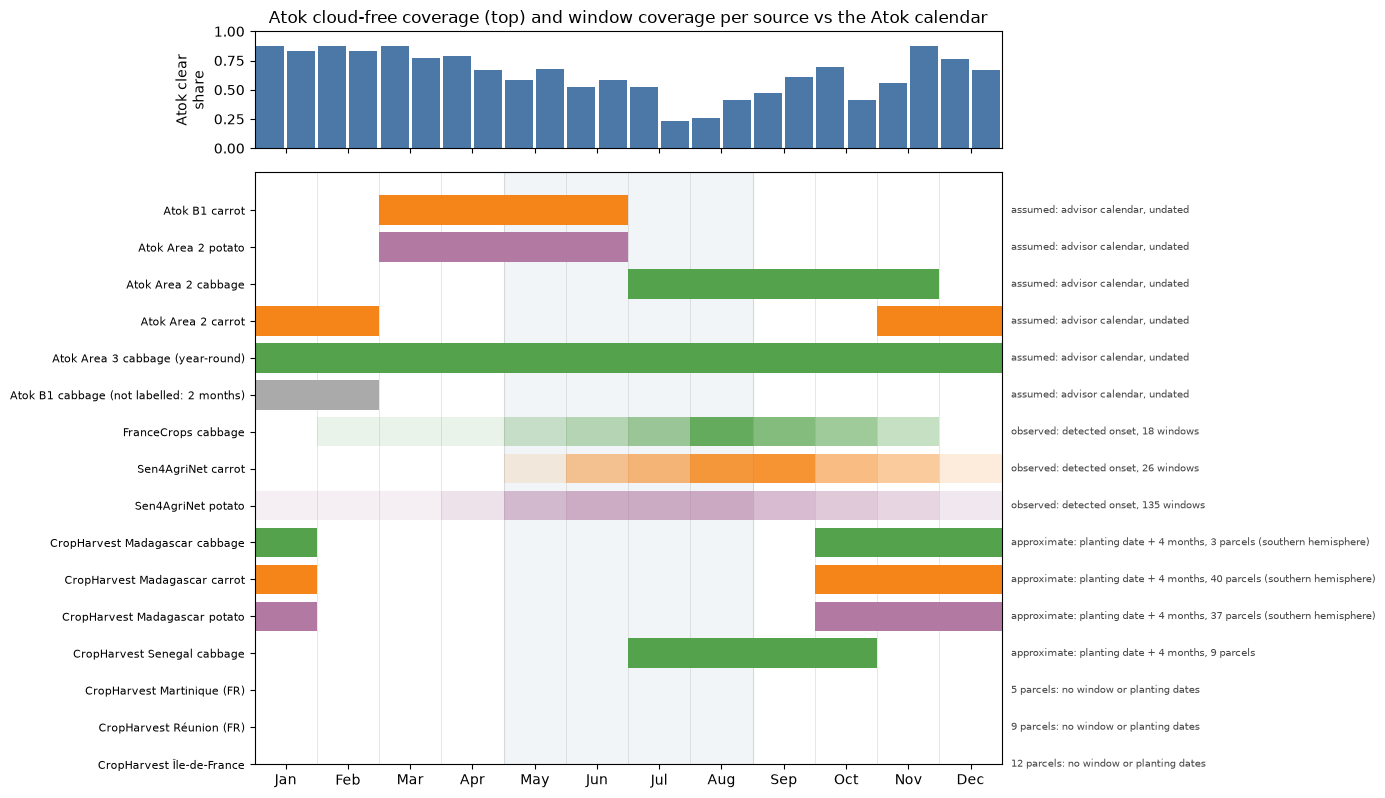

Atok clear share by month: {1: 0.85, 2: 0.85, 3: 0.82, 4: 0.73, 5: 0.63, 6: 0.55, 7: 0.38, 8: 0.34, 9: 0.54, 10: 0.55, 11: 0.72, 12: 0.71}


In [12]:
clear_by_half = atok_data.clear_share_by_half_month(roi)
coverage_rows = external.window_coverage_rows(windows, ch_rows, ch_planting)
plots.half_month_coverage(coverage_rows, clear_by_half, FIGURES)
month_clear = atok_data.monthly_clear_share(clear_by_half)
print("Atok clear share by month:", {m: round(v, 2) for m, v in month_clear.items()})

### 1.4 Temperature profiles: source regions vs Atok

**Source regions.** Monthly mean daily maximum and minimum temperature from TerraClimate (2019-2024, the same years as the PAGASA record; about 4 km), sampled at every parcel centroid and averaged per source region.

**Atok target.**
- **With `pagasa_baguio_path`:** PAGASA Baguio monthly TMAX/TMIN (`data/climate/pagasa_baguio_monthly.csv`, averaged by month), lapse-rate adjusted (6.5 °C/km) from the station elevation to Atok's 2,255 m (about 5 °C cooler).
- **Without it:** a flagged fallback. TerraClimate at the Atok ROI, adjusted from its 4 km cell's mean elevation to 2,255 m. ERA5-Land is not used for Atok: its ~9 km cells blur the elevation even more.

The distance is Euclidean over the 24 monthly values (12 TMAX + 12 TMIN), and regions are ranked from closest to farthest.

In [13]:
climate_points, message = climate.sample_terraclimate(paths, data, roi.lon, roi.lat)
print(message)
climate_profiles = climate.atok_target(climate_points, paths)
print(f"Points with TerraClimate values: {climate_profiles.valid_points} of {climate_profiles.all_points} "
      "(coastal points can fall outside the land mask)")
print("Atok target:", climate_profiles.note)

Loaded cached TerraClimate samples: climate_points.csv
Points with TerraClimate values: 292 of 292 (coastal points can fall outside the land mask)
Atok target: PAGASA Baguio 2019-2024 (1500 m), lapse-adjusted -4.9 °C to 2255 m


In [14]:
distances = climate.distances(climate_profiles)
distances.to_csv(OUTPUT / "climate_distances.csv")
display(distances)

,climate_distance,mean_tmax_diff,mean_tmin_diff,rank
source_region,,,,
CropHarvest: Réunion (FR),18.963,1.697,3.356,1
CropHarvest: Madagascar,22.845,4.601,-0.298,2
FranceCrops: France,27.962,-0.705,-1.985,3
Sen4AgriNet: Catalonia (ES),28.624,-0.164,-0.132,4
CropHarvest: Île-de-France,29.161,-2.187,-3.020,5
CropHarvest: Martinique (FR),53.690,10.379,11.417,6
CropHarvest: Senegal,59.190,13.895,9.649,7


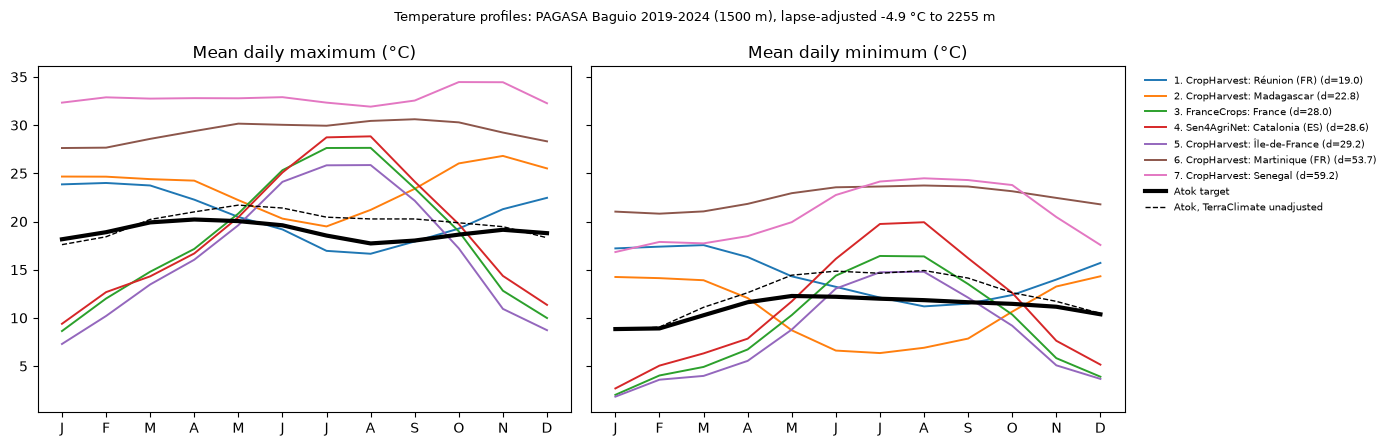

In [15]:
plots.temperature_profiles(climate_profiles, distances, FIGURES)

**Season-aligned distance and monthly differences.** Comparing calendar months penalises southern-hemisphere regions for being out of phase, not for being a different climate. The season-aligned distance shifts southern-hemisphere profiles by 6 months before comparing. The heatmaps show each region's monthly difference from the Atok target (region minus Atok, °C).

In [16]:
region_lat = data.groupby("source_region")["lat"].mean()
distances = climate.add_aligned_distances(distances, climate_profiles, region_lat)
distances.to_csv(OUTPUT / "climate_distances.csv")
display(distances[["climate_distance", "rank", "aligned_distance", "aligned_rank", "hemisphere", "mean_tmax_diff", "mean_tmin_diff"]])

,climate_distance,rank,aligned_distance,aligned_rank,hemisphere,mean_tmax_diff,mean_tmin_diff
source_region,,,,,,,
CropHarvest: Réunion (FR),18.963,1,17.438,1,south,1.697,3.356
CropHarvest: Madagascar,22.845,2,19.007,2,south,4.601,-0.298
FranceCrops: France,27.962,3,27.962,3,north,-0.705,-1.985
Sen4AgriNet: Catalonia (ES),28.624,4,28.624,4,north,-0.164,-0.132
CropHarvest: Île-de-France,29.161,5,29.161,5,north,-2.187,-3.020
CropHarvest: Martinique (FR),53.690,6,53.690,6,north,10.379,11.417
CropHarvest: Senegal,59.190,7,59.190,7,north,13.895,9.649


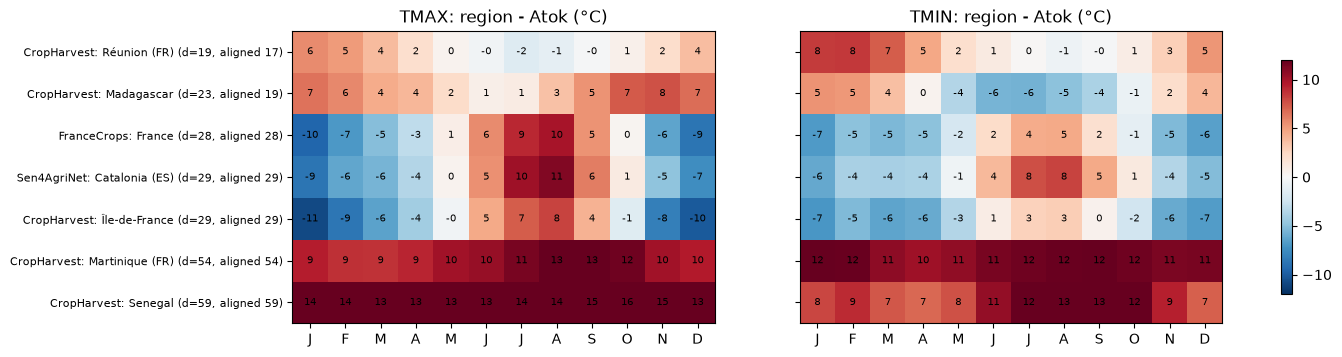

In [17]:
plots.temperature_differences(climate_profiles, distances, FIGURES)

### 1.5 Domain shift and temporal signatures

The model can only transfer if Atok's spectral-temporal trajectories resemble those it was trained on. The first figure compares sources within each crop: median and interquartile range of NDVI, NDRE and NDMI over the 8 half-month bins. The second compares crops within each source, to show how separable the crops are at all. Atok uses its provisional labels.

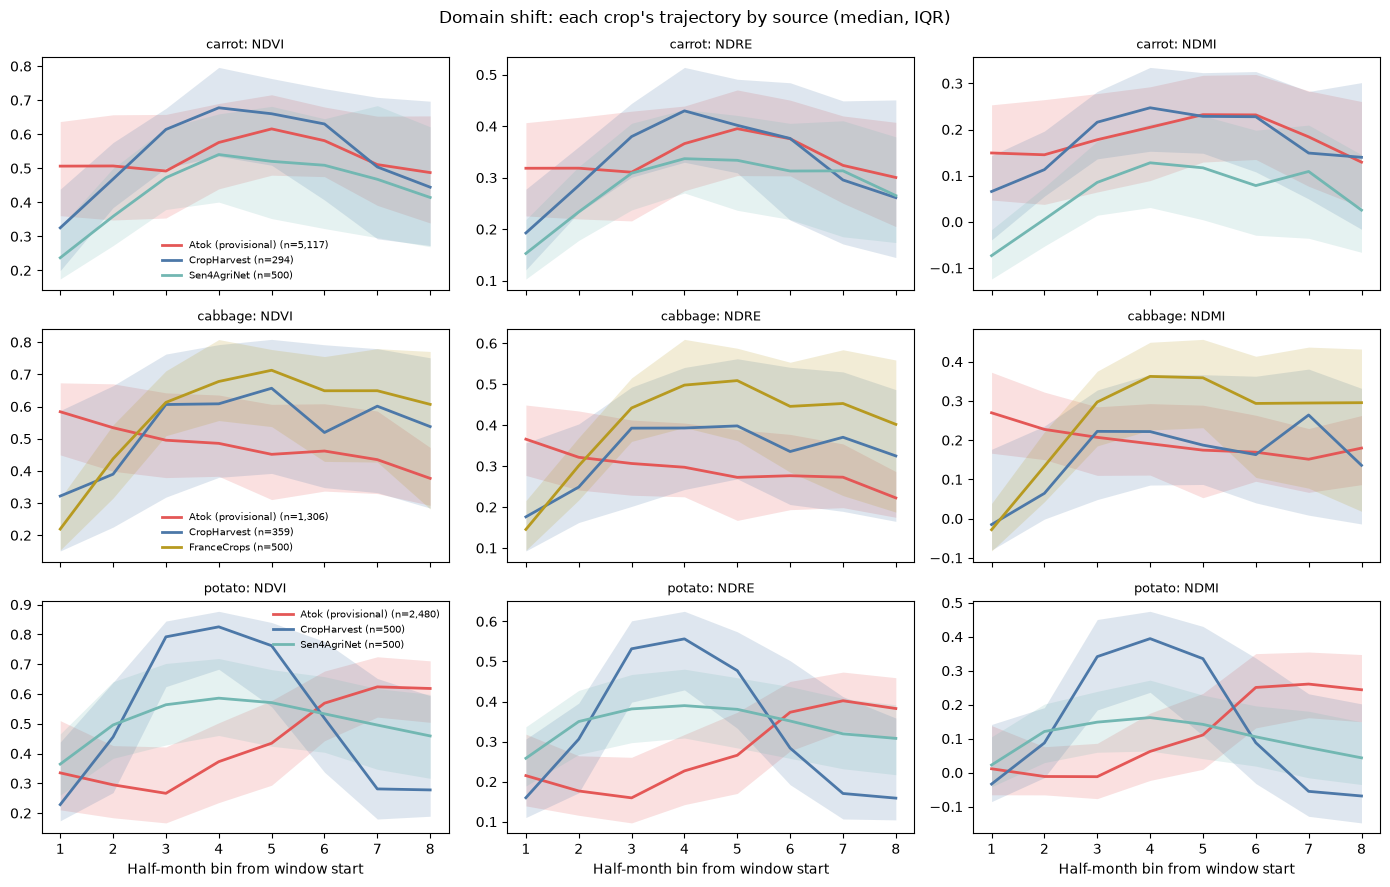

In [18]:
plots.domain_shift_by_crop(data, atok, FIGURES)

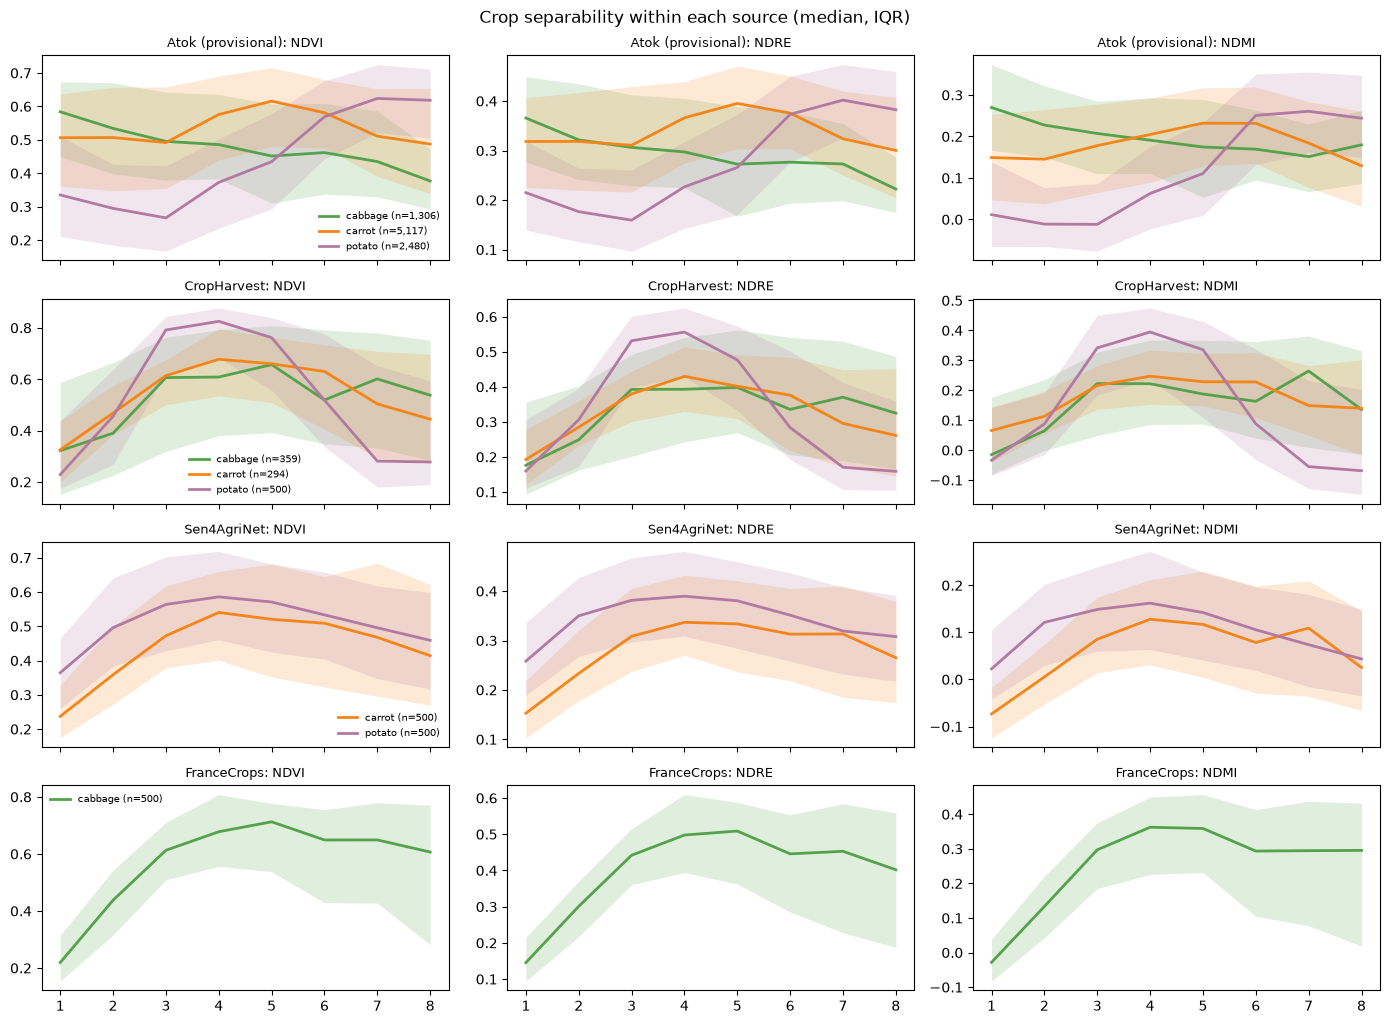

In [19]:
plots.signatures_by_source(data, atok, FIGURES)

**A. Atok against each external region, all nine variables.** Each value is a pixel's mean over its 8 half-months, so these panels show level and spread; the timing is in panel B. The boxplots compare every region with Atok. The heatmap gives the distance between Atok's distribution and each region's for the same crop: the Wasserstein distance in units of the external standard deviation, averaged over the crops the two share. 0 means identical distributions; larger means Atok lies further from what the model learned from that region.

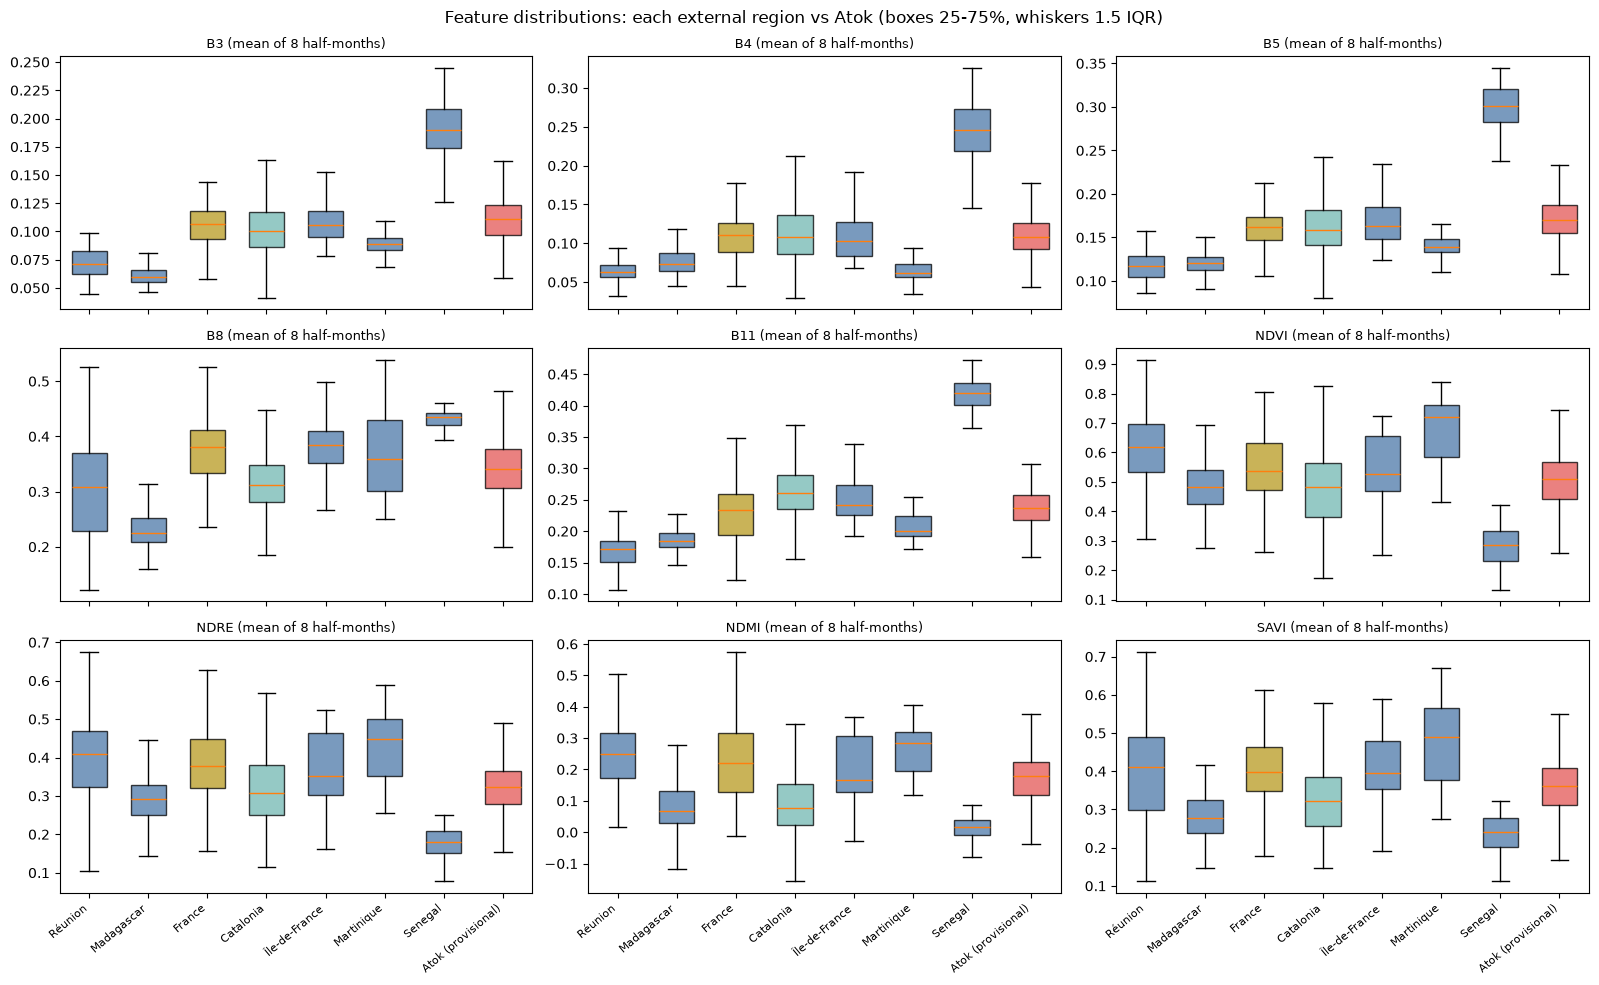

In [20]:
both_means, shift = experiments.atok_shift(data, atok, distances.index)
plots.feature_distributions(both_means, list(distances.index) + [experiments.ATOK], FIGURES)

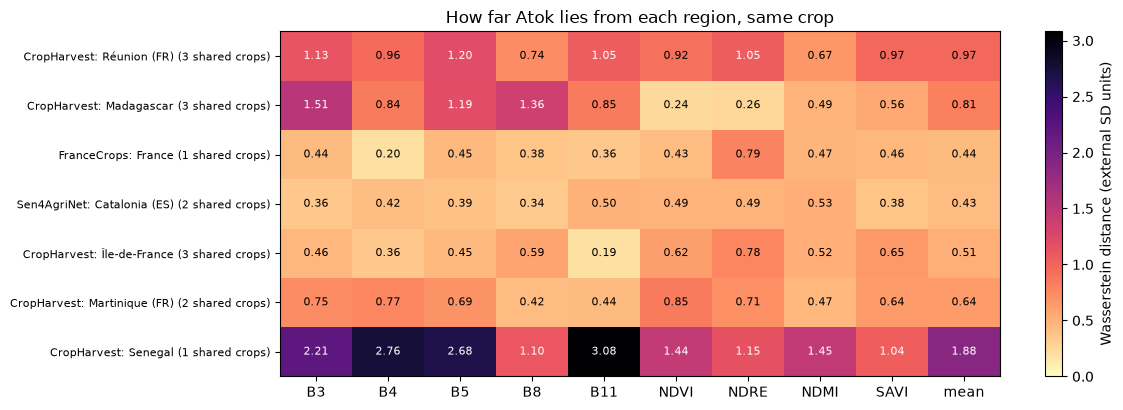

In [21]:
shift.to_csv(OUTPUT / "atok_vs_region_wasserstein.csv")
plots.atok_vs_region_shift(shift, FIGURES)

**B. Crop growth curves and separability.** The first figure shows the mean ± 1 SD of each crop over the 8 half-months, for the verified external data (pooled), for Sen4AgriNet and CropHarvest separately, and for Atok's provisional labels. Comparing within one source shows crop differences without the source confound.

The second figure measures how separable each pair of crops is in each half-month. It uses the Jeffries-Matusita (JM) distance on all 9 variables of that half-month, assuming Gaussian classes. JM runs from 0 to 2: values above about 1.9 are conventionally well separable, and values below 1 mean the classes overlap heavily. Read it to see which growth stage, if any, separates the crops.

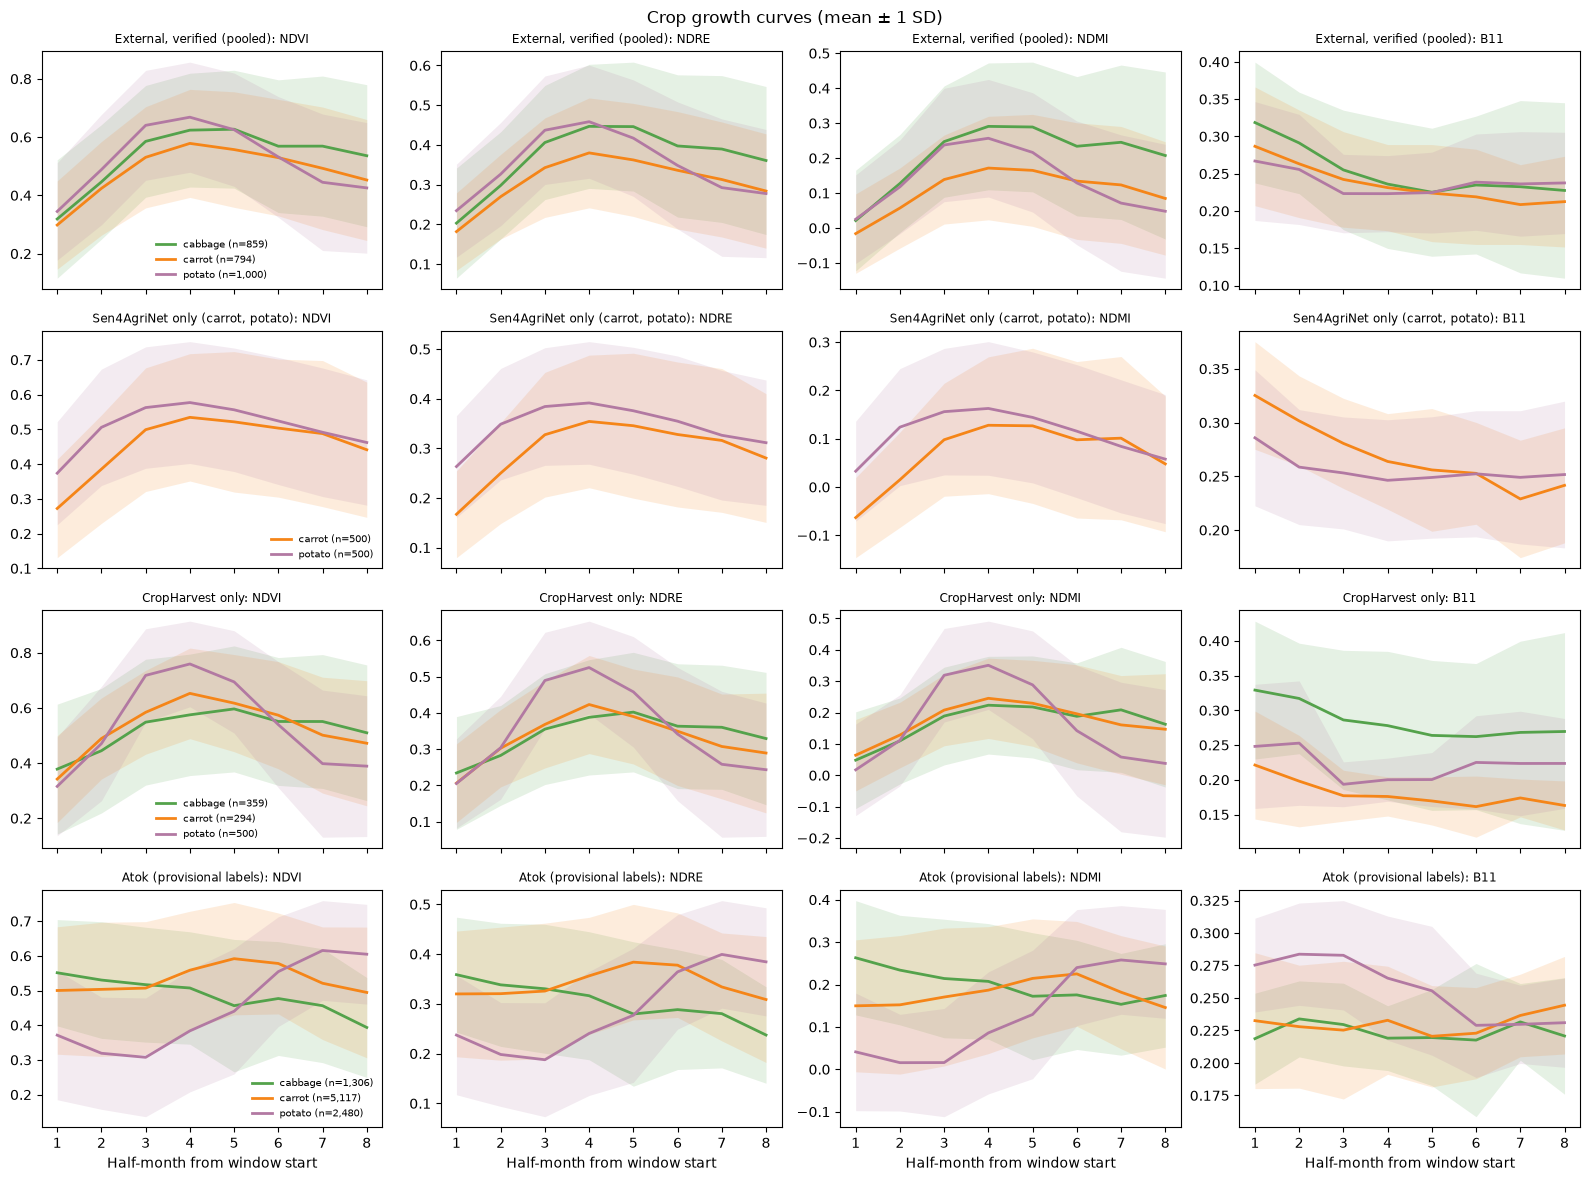

In [22]:
separability_groups = experiments.separability_groups(data, atok)
plots.crop_growth_curves(separability_groups, FIGURES)

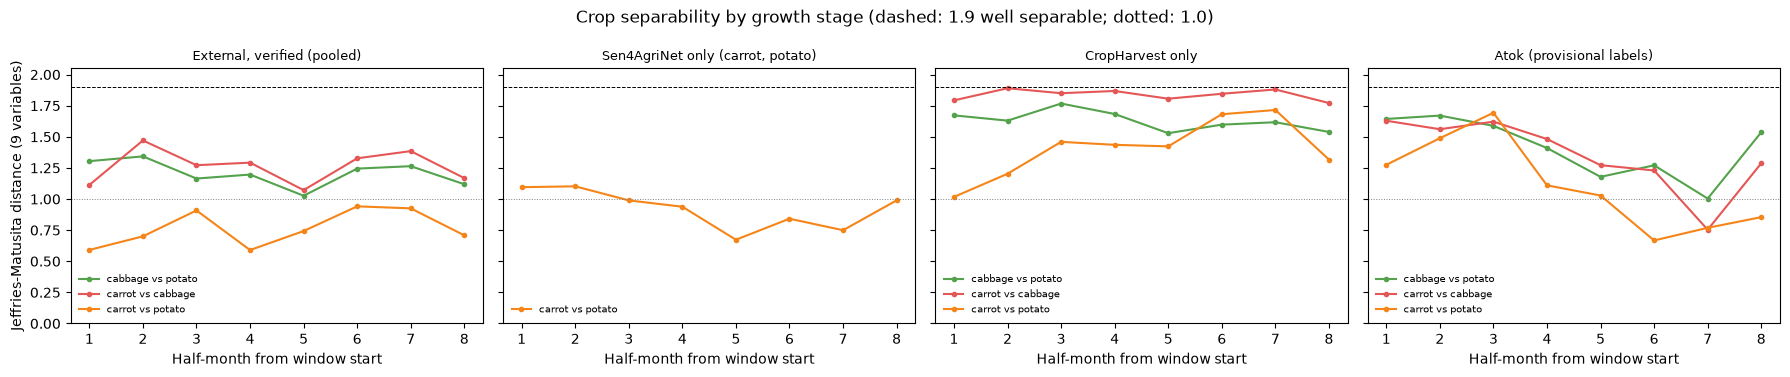

min   max  mean
                                                       JM    JM    JM
group                             pair                               
Atok (provisional labels)         cabbage vs potato  1.00  1.67  1.41
                                  carrot vs cabbage  0.75  1.63  1.35
                                  carrot vs potato   0.67  1.69  1.11
CropHarvest only                  cabbage vs potato  1.53  1.77  1.63
                                  carrot vs cabbage  1.77  1.89  1.84
                                  carrot vs potato   1.02  1.72  1.41
External, verified (pooled)       cabbage vs potato  1.03  1.34  1.21
                                  carrot vs cabbage  1.07  1.47  1.26
                                  carrot vs potato   0.59  0.94  0.76
Sen4AgriNet only (carrot, potato) carrot vs potato   0.67  1.10  0.92

In [23]:
separability = experiments.crop_separability(separability_groups)
separability.to_csv(OUTPUT / "crop_separability_jm.csv", index=False)
plots.crop_separability(separability, separability_groups, FIGURES)
display(separability.pivot_table(index=["group", "pair"], values="JM", aggfunc=["min", "max", "mean"]).round(2))

## 2. Preprocessing QC (Obj 2)

Preprocessing was done and audited in notebooks 01-05: reference extraction, Cloud Score+ masking, bilinear B5/B11 resampling, onset timing checks, complete-window selection and feature construction. See `docs/methodology.md` and `docs/workflow.md`. The tables below summarise the notebook 04 audits for the run that produced the Sen4AgriNet/FranceCrops table. CropHarvest was screened in notebook 03 and has no equivalent audit in that run.

In [24]:
audits = external.preprocessing_audits(paths)
print("Automatic timing checks (parcel-season candidates, Sen4AgriNet + FranceCrops):")
display(audits["timing"]["automatic_timing_status"].value_counts().rename("candidates").to_frame())

Automatic timing checks (parcel-season candidates, Sen4AgriNet + FranceCrops):


,candidates
automatic_timing_status,
passed,314
failed,140


In [25]:
print("Cycle selection status after the timing checks:")
display(audits["selection"].groupby(["source_dataset", "crop", "status"]).size().unstack(fill_value=0))

Cycle selection status after the timing checks:


status                  ambiguous  candidate
source_dataset crop                         
francecrops    cabbage         18         31
sen4agrinet    carrot          26         20
               potato         128         91

In [26]:
print("Usable pixels per crop (complete windows) and the per-crop cap:")
display(audits["usable"])

Usable pixels per crop (complete windows) and the per-crop cap:


,crop,available_usable_pixels,selected_usable_pixels,target_pixels,shortfall_pixels,status
0,carrot,952,500,500,0,target_met
1,cabbage,1352,500,500,0,target_met
2,potato,3001,500,500,0,target_met


## 3. Dataset specification (Obj 3a)

### 3.1 Specification

**Decision on "others".** Built-up and non-crop land become one `others` class, digitised from NAMRIA ELUM CY-2023 non-crop polygons and checked against drone imagery where available. Other crops (lettuce, radish, seedbeds) need their own `other_crop` class once labelled. Neither is trained yet: the external tables have no such rows. Until they are, the maps use the ELUM Crops mask plus an **unknown** label (section 7) for low-probability and out-of-distribution pixels. That reduces wrong labels, but it does not replace these classes.

In [27]:
spec_table = report.dataset_specification()  # text in report.DATASET_SPECIFICATION
spec_table.to_csv(OUTPUT / "dataset_specification.csv", index=False)
display(spec_table.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,item,specification,status
0,Classes,"carrot, cabbage, potato",implemented
1,Classes: others,built-up + non-crop as one class from NAMRIA ELUM CY-2023 non-crop polygons; drone imagery to check,decided; not trained (no external rows)
2,Classes: other crops,"lettuce, radish, seedbeds (B2, Area 5) need an other_crop class",not modelled
3,Unknown (maps),"calibrated top-class probability below the threshold for 70% selective accuracy (4.6b, per model), or out-of-distribution (kNN distance above the 95% quantile of the external test set); minimum coverage requirement 50%",implemented
4,Predictors,"interval: 8 half-months x (B3, B4, B5, B8, B11, NDVI, NDRE, NDMI, SAVI) = 72; shape: 48 temporal-shape features; both classifiers run on both sets",implemented
5,Prototype,"RF on interval predictors (1,000 trees, sqrt, min leaf 2, 50% bootstrap): prespecified; tuned RF and LR reported alongside",implemented
6,Temporal matching: external,Sen4AgriNet/FranceCrops: 8 half-months from detected onset (notebook 04); CropHarvest: window dates not recorded,as exported
7,Temporal matching: Atok,"8 half-months from the calendar planting month: Mar (potato, B1 carrot), Jul (cabbage), Nov (carrot)",implemented
8,Clear-data rule,"external: complete windows only; Atok: >= 6 of 8 clear, gaps interpolated (sensitivity 5-8 in 6.2; 8 = no interpolation)",implemented
9,Climate experiment,"primary: external target regions (verified labels), source sets with >= 5 parcels of each target crop, per-target Spearman and drop-one-source robustness; Atok: exploratory only",implemented


### 3.2 Exclusion funnel and record-level exclusions

Each panel follows one sampling unit (labels, parcel-seasons, parcels, pixels, pixel-windows) and shows the share retained relative to the first step of that unit. The CropHarvest catalogue records get a record-level status, saved with their catalogue index in `cropharvest_record_exclusions.csv`. For the records that reached the training table, the reason other records were dropped at the screening and sampling step was not logged at export. That step is reported as unlogged rather than guessed.

In [28]:
funnel = report.exclusion_funnel(catalogue, ch_match, ch_rows, audits, data, tables, atok, atok_windows)
funnel.to_csv(OUTPUT / "exclusion_funnel.csv", index=False)
display(funnel)

,source,step,unit,count,rule,dropped,retained_%
0,CropHarvest,target-crop labels in the catalogue,labels,1667,"carrot/cabbage/potato names; sweet potato, Chi...",0,100.0
1,CropHarvest,in an exported dataset,labels,1388,"canada, croplands, kenya not exported",279,83.3
2,CropHarvest,table potatoes only,labels,1287,starch potato dropped,101,77.2
3,CropHarvest,parcels in the table,parcels,115,,0,100.0
4,CropHarvest,pixels in the table,pixels,1153,complete windows only,0,100.0
5,Sen4AgriNet + FranceCrops,onset candidates,parcel-seasons,454,,0,100.0
6,Sen4AgriNet + FranceCrops,passed timing checks,parcel-seasons,314,automatic onset timing checks,140,69.2
7,Sen4AgriNet + FranceCrops,window selected,parcel-seasons,179,earliest complete window per parcel,135,39.4
8,Sen4AgriNet + FranceCrops,parcels in the table,parcels,176,,0,100.0
9,Sen4AgriNet + FranceCrops,usable pixels available,pixels,5305,complete windows,0,100.0


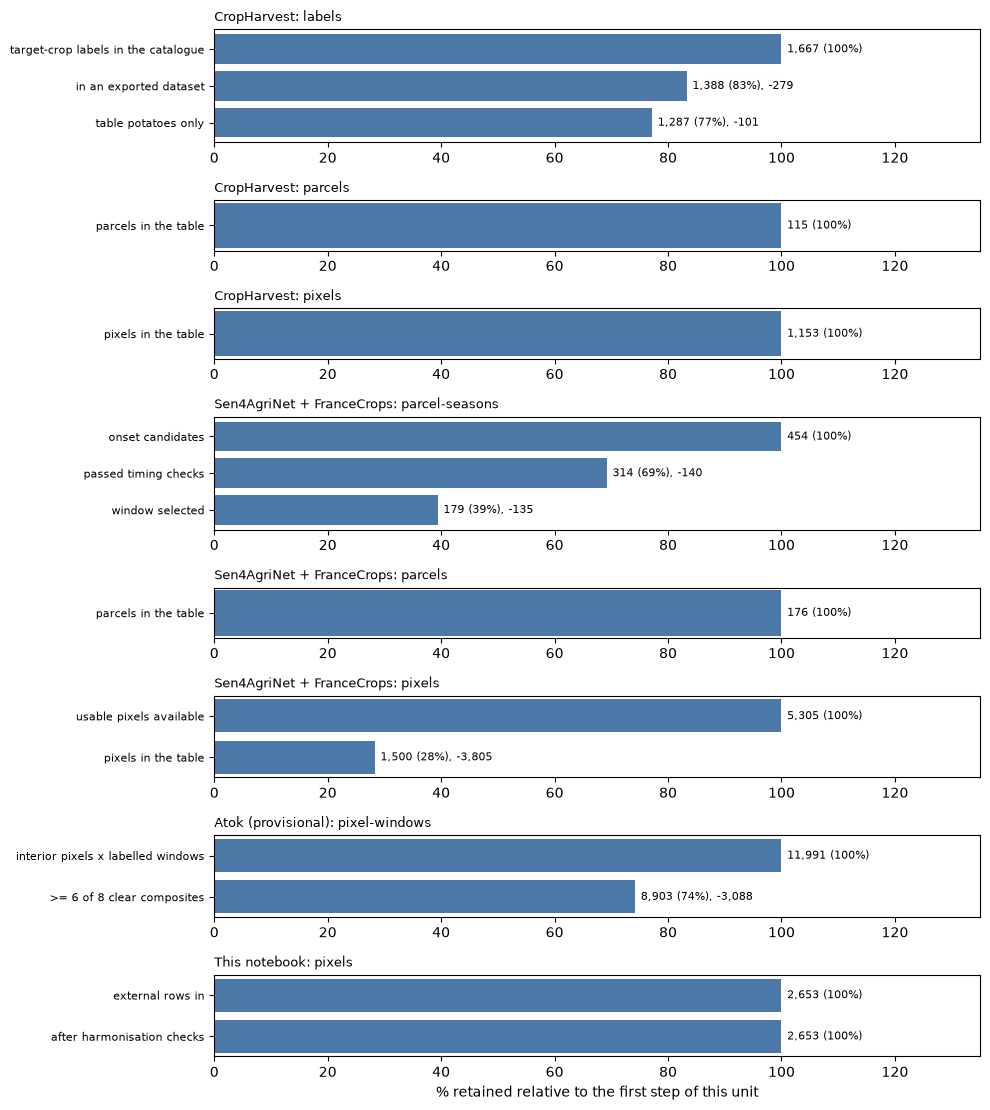

In [29]:
plots.exclusion_funnel(funnel, FIGURES)

In [30]:
records = report.cropharvest_record_status(catalogue, ch_match)
records.to_csv(OUTPUT / "cropharvest_record_exclusions.csv", index=False)
print("CropHarvest catalogue records by status (before) and crop:")
display(pd.crosstab(records["status"], records["target_crop"], margins=True))

CropHarvest catalogue records by status (before) and crop:


target_crop,cabbage,carrot,potato,All
status,,,,
dropped: dataset not exported,76,100,103,279
dropped: not in table (screening or sampling; reason not logged at export),166,474,524,1164
dropped: starch potato,0,0,101,101
kept: matched to a training-table parcel,23,48,52,123
All,265,622,780,1667


In [31]:
print("Crop distribution before and after (labels in the catalogue vs parcels in the training table):")
display(report.crop_distribution_before_after(records, ch_rows))

Crop distribution before and after (labels in the catalogue vs parcels in the training table):


,catalogue labels,table parcels
carrot,622,45
cabbage,265,20
potato,780,50


## 4. External models and diagnostics (Obj 3b)

### 4.1 Same-predictor comparison on the locked test set

Both classifiers run on both predictor sets, so model choice and feature representation can be separated. The **RF on interval predictors is the prespecified prototype**. The **LR on shape predictors was selected by v1's grouped CV**. No configuration below was chosen using the test set. Every table has two baselines: always predicting the most common class, and the expected score of guessing with the class shares. **Balanced accuracy** is the mean producer's accuracy (recall) over crops. Producer's accuracy is the share of a crop that is found; user's accuracy is the share of mapped pixels of a crop that are right.

In [32]:
FOLDS = models.grouped_folds(development)  # the same folds as v1's CV
pooled, test_results = models.fit_pooled_models(development, test)  # models.MODEL_SPECS
test_results.to_csv(OUTPUT / "external_test_results.csv", index=False)
display(test_results)

,model,n,OA,balanced_acc,macro_F1,PA_carrot,UA_carrot,PA_cabbage,UA_cabbage,PA_potato,UA_potato,macro_F1_95CI
0,Baseline: always potato,634,0.377,0.333,0.183,0.000,NaN,0.000,NaN,1.000,0.377,
1,Baseline: guess with class shares (expected),634,0.337,0.333,0.333,0.330,0.330,0.293,0.293,0.377,0.377,
2,"RF, interval (prespecified prototype)",634,0.576,0.579,0.581,0.435,0.798,0.694,0.617,0.607,0.466,0.403-0.704
3,"LR, interval",634,0.653,0.665,0.657,0.713,0.828,0.780,0.560,0.502,0.615,0.475-0.776
4,"RF, shape",634,0.418,0.399,0.378,0.196,0.526,0.290,0.370,0.711,0.415,0.271-0.502
5,"LR, shape (v1 CV-selected)",634,0.544,0.556,0.546,0.526,0.683,0.715,0.482,0.427,0.518,0.417-0.670


### 4.2 Grouped CV from v1 (development parcels)

v1's grouped 5-fold CV (same folds) for every design × model, mean ± sd macro-F1. Read along a row to compare models on the same predictors, and down a column to compare predictor sets for the same model.

In [33]:
v1_cv = pd.read_csv(paths.v1 / "cv_summary.csv")
v1_cv = v1_cv[(v1_cv["grouping"] == "split_unit") & (v1_cv["weighted"].astype(str) == "True")]
display(v1_cv.assign(score=v1_cv["macro_f1_mean"].map("{:.3f}".format) + " ± " + v1_cv["macro_f1_std"].map("{:.3f}".format))
        .pivot(index="design", columns="model", values="score"))

model,gradient_boosting,logistic_regression,random_forest
design,,,
interval_and_shape,0.518 ± 0.113,0.558 ± 0.091,0.512 ± 0.124
interval_only,0.516 ± 0.102,0.555 ± 0.100,0.518 ± 0.119
shape_only,0.479 ± 0.094,0.558 ± 0.092,0.470 ± 0.080


### 4.3 RF tuning and overfitting (grouped CV)

The prototype's settings were prespecified, not tuned. The grid below covers minimum leaf size, features per split and maximum depth on the interval predictors. Every configuration uses the same 5 grouped folds and 2 seeds, with 500 trees each to keep the run short. Training and validation macro-F1 are reported together, so the gap (overfitting) is visible. The best and the prototype configurations are then rerun with **source-balanced** weights. The best configuration by validation macro-F1 is refitted with 1,000 trees and scored once on the locked test set, as a reported alternative to the prototype.

In [34]:
tuning = experiments.tuning_grid(development, FOLDS, models.PROTOTYPE_PARAMS)  # experiments.TUNING_GRID
tuning.to_csv(OUTPUT / "rf_tuning_grid.csv", index=False)
display(tuning)
TUNED_PARAMS = experiments.best_params(tuning)
print("Best by grouped CV:", TUNED_PARAMS)

,min_samples_leaf,max_features,max_depth,validation_macro_F1,validation_sd,train_macro_F1,gap,prototype
0,25,0.5,NaN,0.530,0.104,0.738,0.208,False
1,25,0.5,8.0,0.530,0.104,0.738,0.208,False
2,1,sqrt,NaN,0.527,0.119,0.985,0.458,False
3,2,0.5,NaN,0.526,0.096,0.975,0.449,False
4,1,0.5,NaN,0.525,0.090,0.982,0.457,False
5,10,0.5,NaN,0.520,0.098,0.876,0.357,False
6,2,sqrt,NaN,0.520,0.111,0.976,0.456,True
7,10,sqrt,8.0,0.519,0.111,0.846,0.327,False
8,5,0.5,NaN,0.518,0.095,0.942,0.424,False
9,10,0.5,8.0,0.517,0.098,0.873,0.357,False


Best by grouped CV: {'min_samples_leaf': 25, 'max_features': 0.5, 'max_depth': None}


In [35]:
weighting = experiments.weighting_comparison(development, FOLDS, {"prototype": models.PROTOTYPE_PARAMS, "tuned": TUNED_PARAMS})
weighting.to_csv(OUTPUT / "rf_weighting_comparison.csv", index=False)
display(weighting)

,configuration,weighting,validation_macro_F1,validation_sd,train_macro_F1,gap
0,prototype,crop and parcel,0.520,0.111,0.976,0.456
1,prototype,source-balanced,0.529,0.128,0.985,0.456
2,tuned,crop and parcel,0.530,0.104,0.738,0.208
3,tuned,source-balanced,0.532,0.091,0.789,0.257


In [36]:
TUNED = "RF, interval (tuned by grouped CV)"
pooled[TUNED] = (models.fit_rf(development, INTERVAL, **TUNED_PARAMS), INTERVAL)
test_results = models.append_test_row(test_results, models.test_row(TUNED, pooled[TUNED][0], test, INTERVAL))
test_results.to_csv(OUTPUT / "external_test_results.csv", index=False)
display(test_results.tail(1))

,model,n,OA,balanced_acc,macro_F1,PA_carrot,UA_carrot,PA_cabbage,UA_cabbage,PA_potato,UA_potato,macro_F1_95CI
6,"RF, interval (tuned by grouped CV)",634,0.579,0.593,0.584,0.579,0.738,0.774,0.562,0.427,0.477,0.400-0.723


### 4.4 Learning curves by crop

These use the prototype's settings, including 1,000 trees, and 3 seeds per training fraction. Training units are subsampled within each crop in every grouped fold. The panels show validation macro-F1 against training macro-F1, and validation recall per crop. If validation keeps rising as parcels are added, more data should help. If it flattens while the training-validation gap stays large, more data from the same sources will not close the gap: the cause is more likely source differences or label inconsistency.

In [37]:
curve = experiments.learning_curve(development, FOLDS)
curve.to_csv(OUTPUT / "learning_curve.csv", index=False)
curve_means = curve.groupby("fraction").mean()
display(curve_means[["train_parcels", "train_macro_F1", "validation_macro_F1"] + [f"recall_{c}" for c in CLASSES]])

,train_parcels,train_macro_F1,validation_macro_F1,recall_carrot,recall_cabbage,recall_potato
fraction,,,,,,
0.2,37.0,0.989,0.432,0.232,0.363,0.777
0.4,74.6,0.975,0.485,0.254,0.459,0.797
0.6,111.8,0.981,0.499,0.267,0.467,0.813
0.8,149.4,0.976,0.512,0.233,0.525,0.831
1.0,186.4,0.976,0.518,0.251,0.507,0.844


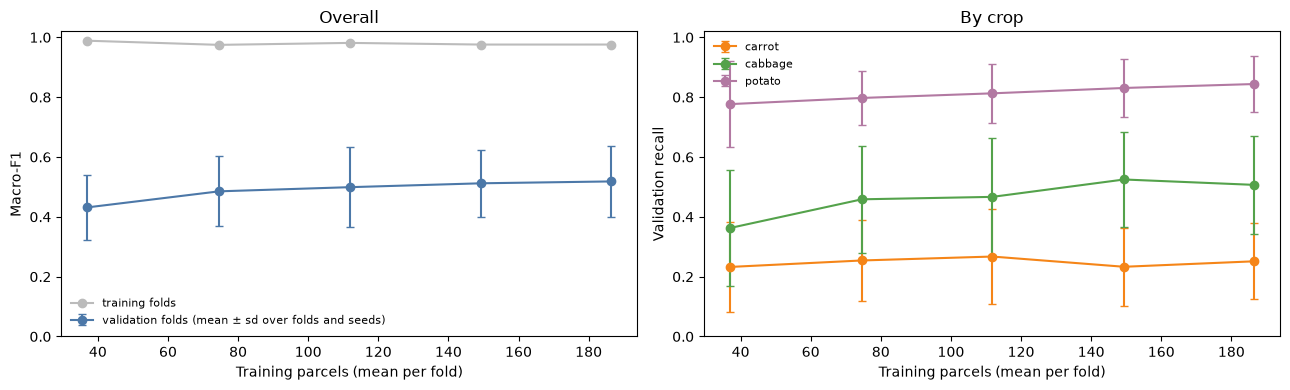

In [38]:
plots.learning_curves(curve, FIGURES)

### 4.5 Grouped permutation importance and feature-family ablation

Predictors in neighbouring half-months and related indices are strongly correlated, so permuting single columns understates shared information, and summing those drops is misleading. Here whole groups are permuted together on each grouped validation fold (5 repeats):

- **one variable across all 8 bins**, and
- **one bin across all 9 variables**.

Negative values mean shuffling the group did not hurt, or slightly helped, on that fold: the group carries no usable signal there. The ablation refits the RF without each variable family and reports the change in validation macro-F1.

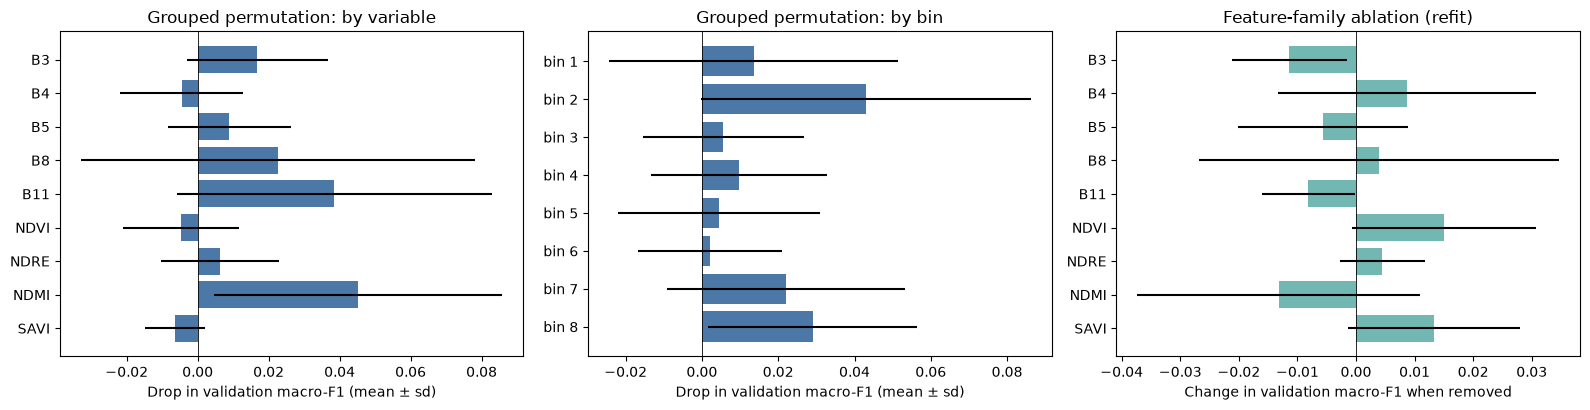

In [39]:
importance, ablation = experiments.importance_and_ablation(development, FOLDS)
importance.to_csv(OUTPUT / "grouped_permutation_importance.csv", index=False)
ablation.to_csv(OUTPUT / "family_ablation.csv", index=False)
plots.importance_ablation(importance, ablation, FIGURES)

### 4.6 Calibration, abstention threshold and out-of-distribution check

The top-class probability of a Random Forest is not automatically a calibrated probability of being right. Reliability diagrams and expected calibration error (ECE) are computed on out-of-fold predictions for the development parcels, and on the locked test set; both have verified external labels. The selective-prediction curve shows accuracy against the share of predictions kept. The **abstention threshold** is the lowest top-class probability whose out-of-fold kept predictions reach the target selective accuracy. It is set on development data and then checked on the test set.

The **out-of-distribution** check is the mean distance to the 5 nearest development samples in standardised interval-feature space. A sample is flagged when it is farther than the chosen quantile of the external test samples' distances. Calibration on Atok cannot be assessed until verified Atok labels exist.

In [40]:
oof = experiments.out_of_fold(development, FOLDS)  # prototype RF and v1's LR
reliability_curves, calibration = experiments.calibration_check(development, test, pooled, oof)
calibration.to_csv(OUTPUT / "calibration.csv", index=False)
abstention = experiments.raw_abstention(development, test, pooled, oof[PROTOTYPE])

In [41]:
distance_to_training = models.DistanceToTraining(development)
test_distance = distance_to_training(test)
OOD_THRESHOLD = float(np.quantile(test_distance, OOD_QUANTILE))
atok_distance = distance_to_training(atok)
atok["ood"] = atok_distance > OOD_THRESHOLD

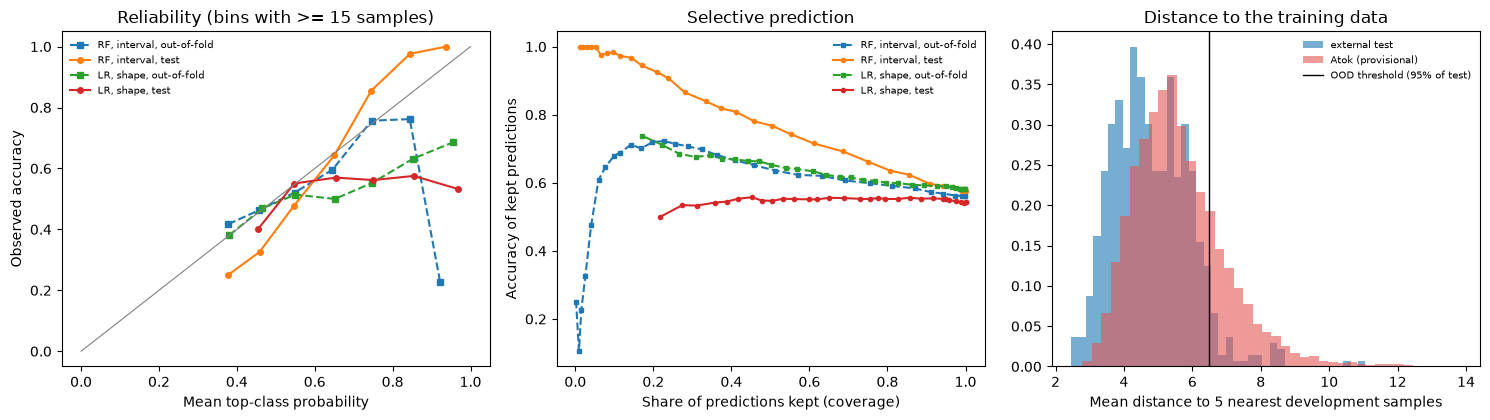

In [42]:
plots.calibration_selective_ood(reliability_curves, test_distance, atok_distance, OOD_THRESHOLD, FIGURES)

In [43]:
display(calibration)
print("Abstention threshold:", abstention)
print(f"Out-of-distribution: {atok['ood'].mean():.0%} of Atok pixel-windows vs {1 - OOD_QUANTILE:.0%} of the external test set by construction")

,model,data,ECE,accuracy,mean_confidence
0,"RF, interval (prespecified prototype)",out-of-fold,0.039,0.560,0.589
1,"RF, interval (prespecified prototype)",test,0.081,0.576,0.604
2,"LR, shape (v1 CV-selected)",out-of-fold,0.173,0.580,0.753
3,"LR, shape (v1 CV-selected)",test,0.228,0.544,0.766


Abstention threshold: {'threshold': 0.66, 'target_accuracy': 0.7, 'oof_coverage': 0.28875681030212974, 'oof_accuracy_kept': 0.7066895368782161, 'test_coverage': 0.334384858044164, 'test_accuracy_kept': 0.839622641509434, 'reached': True}
Out-of-distribution: 22% of Atok pixel-windows vs 5% of the external test set by construction


### 4.6b Fitting a calibration, and whether the threshold transfers to new regions

Section 4.6 only **measured** calibration. Here the prototype's probabilities are **calibrated**, by one of two methods fitted on the grouped out-of-fold predictions for the development parcels:

- **temperature scaling:** one parameter; it never changes the predicted crop;
- **matrix scaling:** a multinomial logistic map from log-probabilities.

**No calibration** (the raw probabilities) is the third candidate. Whichever of the three has the lowest cross-fitted ECE on development data is used; the test set plays no part in that choice. If neither fitted method beats the raw probabilities, the raw ones are kept, and that is a result: fitting was tried and did not help. To evaluate it honestly:

- **cross-fitted:** each fold's out-of-fold predictions are recalibrated by a calibrator fitted on the other folds only;
- **held-out:** the final calibrator, fitted on all out-of-fold predictions, is scored once on the locked test set.

The abstention threshold is then chosen on the cross-fitted calibrated probabilities. The target is the same: kept predictions reach the target selective accuracy.

**Does the threshold transfer?** Each region in turn is held out. The model, its out-of-fold predictions, the calibrator and the threshold all come from the other regions only. The threshold is then applied to the unseen region. If the kept predictions in unseen regions fall well short of the target, a threshold set on external data cannot be trusted in Atok either. Atok's calibration remains unknown until verified Atok labels exist.

In [44]:
calibration_fit = experiments.fit_calibration(development, test, pooled, FOLDS, oof[PROTOTYPE])
CAL_METHOD = calibration_fit["method"]
calibration_fit["table"].to_csv(OUTPUT / "calibration_fitted.csv", index=False)
print("Calibration method chosen by cross-fitted ECE on development data:", CAL_METHOD,
      f"(temperature {calibration_fit['calibrator'].temperature:.2f})" if CAL_METHOD == "temperature" else "",
      "- no fitted calibration improved on the raw probabilities, so they are kept" if CAL_METHOD == "none" else "")
display(calibration_fit["table"])
print(f"Threshold on calibrated probabilities: {calibration_fit['threshold']} (target {config.TARGET_SELECTIVE_ACCURACY:.0%} "
      f"reached out of fold: {calibration_fit['reached']}); locked test: keeps {calibration_fit['test_coverage']:.0%} "
      f"at {calibration_fit['test_accuracy_kept']:.0%} accuracy")

Calibration method chosen by cross-fitted ECE on development data: none  - no fitted calibration improved on the raw probabilities, so they are kept


,data,probabilities,ECE,accuracy
0,"development, out of fold",none (raw),0.039,0.560
1,"development, out of fold",temperature (cross-fitted),0.063,0.560
2,"development, out of fold",matrix (cross-fitted),0.082,0.534
3,locked test,raw,0.081,0.576
4,locked test,none (chosen),0.081,0.576


Threshold on calibrated probabilities: 0.66 (target 70% reached out of fold: True); locked test: keeps 33% at 84% accuracy


In [45]:
threshold_transfer, transfer_curves = experiments.threshold_transfer(data, distances.index, CAL_METHOD)
threshold_transfer.to_csv(OUTPUT / "threshold_transfer_by_region.csv", index=False)
display(threshold_transfer)
print(f"Threshold transfers (kept accuracy >= {config.TARGET_SELECTIVE_ACCURACY:.0%}) in "
      f"{int(threshold_transfer['meets target'].sum())} of {len(threshold_transfer)} unseen regions")

,held_out_region,n,threshold (from other regions),ECE raw,ECE calibrated,accuracy (all),coverage at threshold,accuracy of kept,meets target
0,CropHarvest: Réunion (FR),260,0.62,0.217,0.217,0.773,0.308,0.925,True
1,CropHarvest: Madagascar,266,0.68,0.213,0.213,0.560,0.109,0.276,False
2,FranceCrops: France,500,0.56,0.342,0.342,0.192,0.372,0.145,False
3,Sen4AgriNet: Catalonia (ES),1000,0.34,0.526,0.526,0.122,0.999,0.121,False
4,CropHarvest: Île-de-France,341,0.52,0.401,0.401,0.340,0.845,0.274,False
5,CropHarvest: Martinique (FR),159,0.60,0.216,0.216,0.252,0.025,0.000,False
6,CropHarvest: Senegal,127,0.58,0.477,0.477,0.000,0.063,0.000,False


Threshold transfers (kept accuracy >= 70%) in 1 of 7 unseen regions


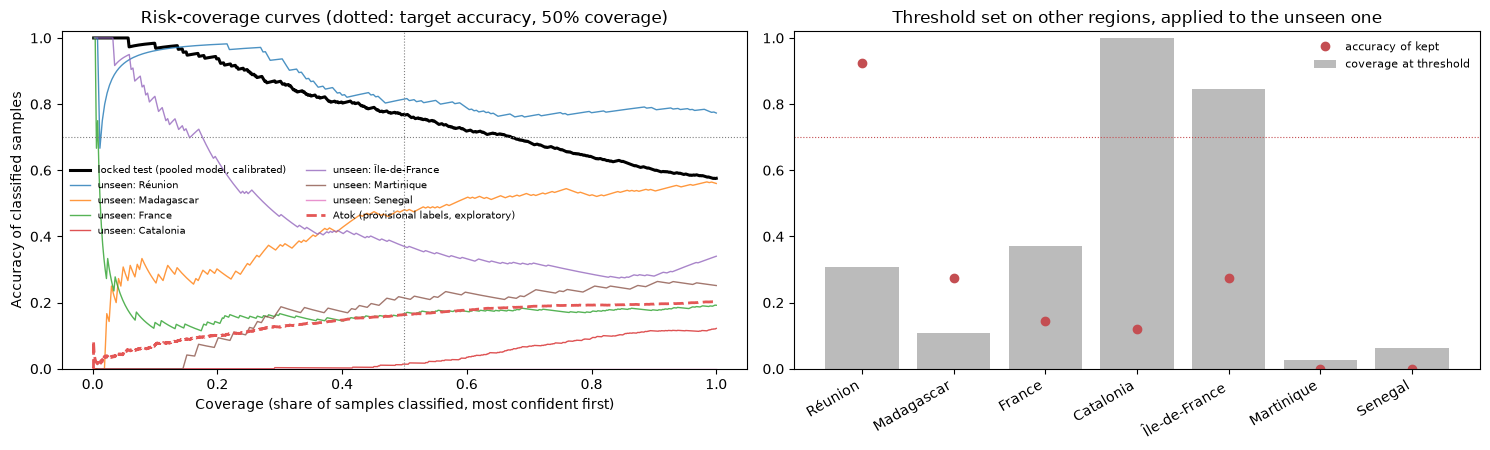

In [46]:
atok_calibrated = models.apply_calibrator(calibration_fit["calibrator"], models.aligned_proba(pooled[PROTOTYPE][0], atok, INTERVAL))
plots.threshold_transfer(calibration_fit["test_calibrated"], test, transfer_curves, threshold_transfer, atok_calibrated, atok, FIGURES)

### 4.7 Transfer to unseen regions

The locked test set mixes regions that are also in training, so it does not measure transfer to a new region. Two experiments do.

- **Leave one region out:** train the prototype RF on every other region (all their parcels) and test on the held-out region. Crops that the remaining regions never contain cannot be predicted and are listed.
- **Single-region transfer:** train on one region (regions with at least 2 crops) and test on every other region, plus provisional Atok. Scores over 1, 2 or 3 shared crops are different tasks, so they are shown on separate panels. The comparable measure is the one-vs-rest AUC per crop that follows.

In [47]:
REGIONS = list(distances.index)
loro = experiments.leave_one_region_out(data, REGIONS)
loro.to_csv(OUTPUT / "leave_one_region_out.csv", index=False)
display(loro)

,held_out_region,parcels,crops,crops missing from training,majority_OA,n,OA,balanced_acc,macro_F1,PA_carrot,PA_cabbage,PA_potato
0,CropHarvest: Réunion (FR),9,"cabbage, carrot, potato",-,0.600,260,0.781,0.754,0.622,0.640,0.750,0.872
1,CropHarvest: Madagascar,80,"cabbage, carrot, potato",-,0.523,266,0.538,0.350,0.313,0.187,0.000,0.863
2,FranceCrops: France,18,cabbage,-,1.000,500,0.198,0.198,0.331,NaN,0.198,NaN
3,Sen4AgriNet: Catalonia (ES),158,"carrot, potato",-,0.500,1000,0.119,0.119,0.189,0.038,NaN,0.200
4,CropHarvest: Île-de-France,12,"cabbage, carrot, potato",-,0.601,341,0.337,0.328,0.249,0.000,0.671,0.312
5,CropHarvest: Martinique (FR),5,"cabbage, carrot",-,0.931,159,0.302,0.246,0.370,0.182,0.311,NaN
6,CropHarvest: Senegal,9,cabbage,-,1.000,127,0.000,0.000,0.000,NaN,0.000,NaN


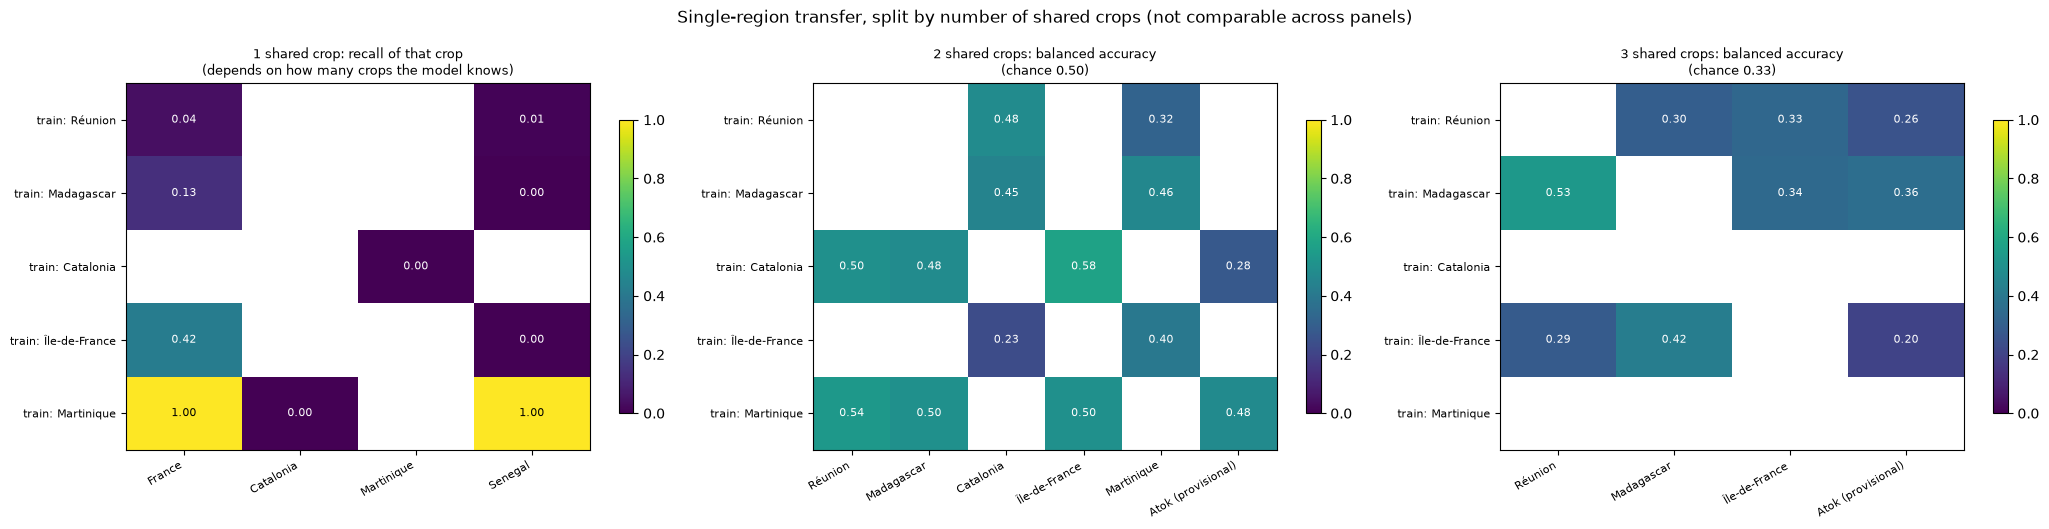

In [48]:
transfer = experiments.transfer_matrix(data, atok, REGIONS)
transfer["matrix"].to_csv(OUTPUT / "transfer_matrix_balanced_accuracy.csv")
transfer["shared_count"].to_csv(OUTPUT / "transfer_matrix_shared_crops.csv")
plots.transfer_matrix(transfer, FIGURES)

**One-vs-rest transfer per crop (comparable across pairs).** For each crop, a train → test pair qualifies only when **both** regions contain that crop and at least one other crop. The other crops in the test region are then valid negatives. The score is the ROC AUC of the model's probability for that crop: chance is 0.5 whatever the number of crops, and it needs no threshold. These are the transfer scores used for the similarity analysis (C) below.

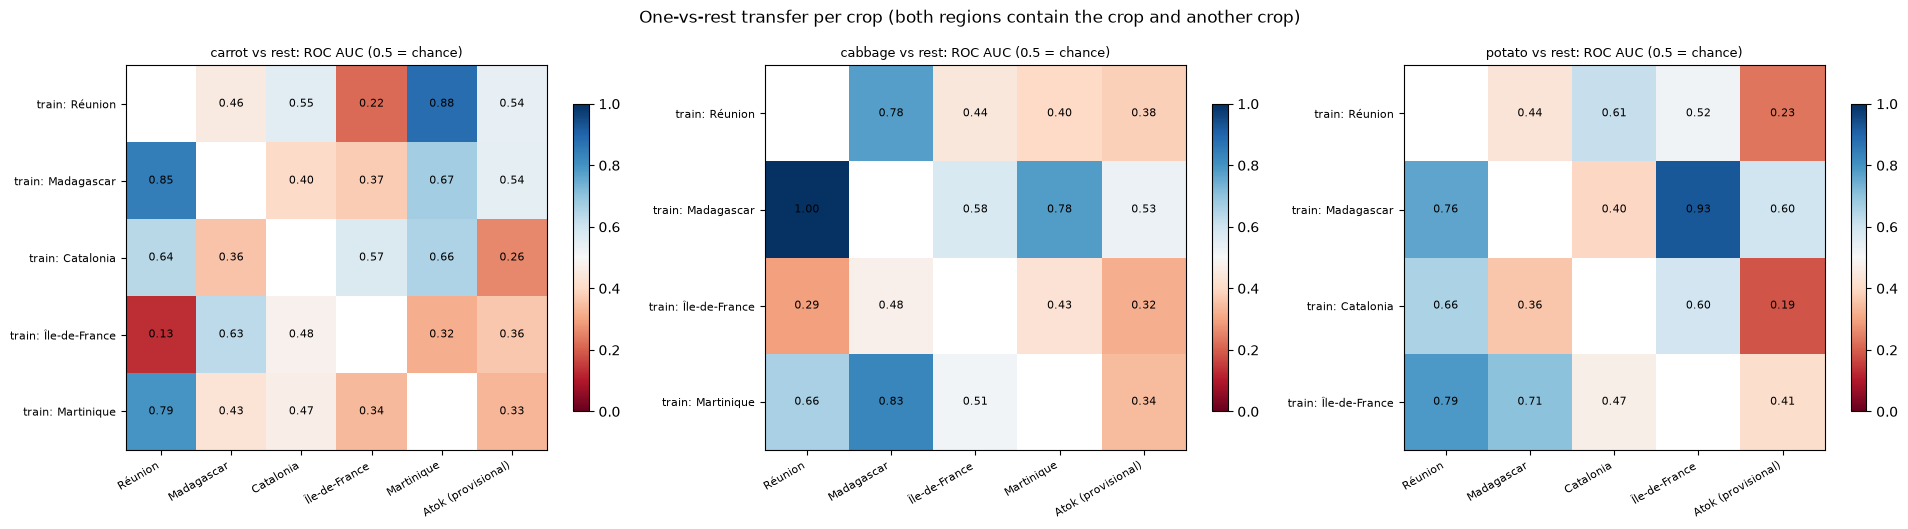

count   mean    min    max
crop    test                                          
cabbage Atok (provisional)      4  0.394  0.320  0.531
        external               12  0.598  0.295  0.995
carrot  Atok (provisional)      5  0.408  0.259  0.544
        external               20  0.511  0.131  0.881
potato  Atok (provisional)      4  0.358  0.186  0.598
        external               12  0.603  0.360  0.925

In [49]:
similarity = climate.RegionSimilarity(climate_profiles, data, roi.lon, roi.lat)  # season-aligned climate and km
ovr = experiments.one_vs_rest_transfer(data, atok, transfer, similarity)
ovr.to_csv(OUTPUT / "transfer_one_vs_rest_auc.csv", index=False)
plots.one_vs_rest_auc(ovr, transfer, FIGURES)
display(experiments.auc_summary(ovr))

**C. Does similarity predict transfer?** Each point is one train → test → crop combination from the one-vs-rest table, so every point is scored on the same scale (AUC, chance 0.5). The x-axis is either the season-aligned climate distance (the TMAX/TMIN measure of section 1.4) or the great-circle distance between the region centroids. If similarity drives transfer, AUC should fall as distance grows. The points share regions and crops, so they are not independent: ρ is descriptive.

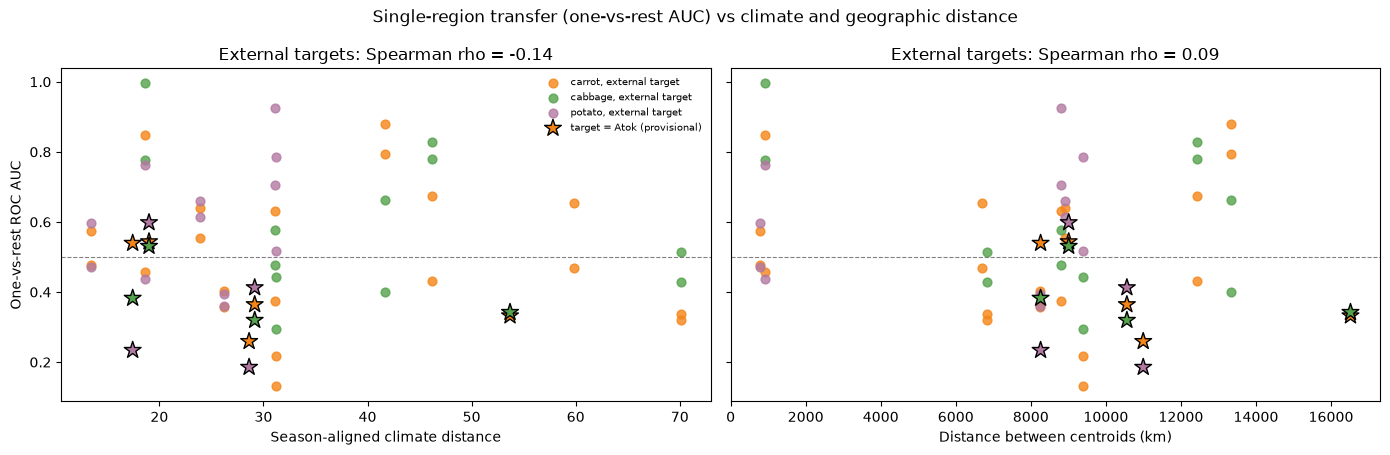

,points,n,measure,spearman_rho,p (not independent)
0,all points,57,climate_distance,-0.108,0.426
1,all points,57,geographic_km,-0.097,0.473
2,external targets only,44,climate_distance,-0.143,0.354
3,external targets only,44,geographic_km,0.085,0.582
4,"external, carrot only",20,climate_distance,-0.175,0.460
5,"external, carrot only",20,geographic_km,0.088,0.714
6,"external, cabbage only",12,climate_distance,-0.198,0.538
7,"external, cabbage only",12,geographic_km,-0.184,0.568
8,"external, potato only",12,climate_distance,0.297,0.349
9,"external, potato only",12,geographic_km,0.382,0.221


In [50]:
pair_stats = experiments.similarity_correlations(ovr)
pair_stats.to_csv(OUTPUT / "transfer_similarity_correlations.csv", index=False)
plots.transfer_vs_similarity(ovr, pair_stats, FIGURES)
display(pair_stats)

## 5. Climate-matching experiment

### 5.1 Primary test: external target regions with verified labels

The climate question is tested where the labels can be trusted. Each external region with at least two crops becomes a **target** in turn. Training sets are combinations of the other regions. A combination is eligible only if it holds at least `MIN_PARCELS_PER_CROP` parcels of every crop the target contains, so every set is scored on the same task for a given target.

For each eligible set:

- an RF (prototype settings, 500 trees) is trained on all parcels of those regions and scored on all parcels of the target: balanced accuracy over the target's crops;
- the set's climate distance to the target is the parcel-weighted mean of its regions' season-aligned distances; the geographic distance is computed the same way.

Within each target, Spearman's ρ between climate distance and transfer, and a slope adjusted for training size, show whether closer climates transfer better. The robustness check reruns ρ after dropping every set that contains any one source region. **If the effect is real, ρ should be negative in most targets and survive removing any single source.** Atok is not used here.

In [51]:
TARGETS, external_sets = experiments.climate_external_targets(data, REGIONS, similarity)
external_sets.to_csv(OUTPUT / "climate_external_targets.csv", index=False)
target_stats = experiments.climate_target_stats(data, external_sets, REGIONS)
target_stats.to_csv(OUTPUT / "climate_external_summary.csv", index=False)
display(target_stats)

,target,eligible_sets,crops,rho_climate,p_climate,rho_geographic,slope_climate_adj_size,rho_range_dropping_one_source,negative_after_every_drop,best_vs_worst_climate_tercile
0,CropHarvest: Réunion (FR),43,3,-0.486,9.620e-04,-0.293,-6.473e-02,-0.68 to -0.30,True,0.123
1,CropHarvest: Madagascar,31,3,-0.136,4.661e-01,-0.214,-7.816e-03,-0.62 to +0.26,False,0.017
2,Sen4AgriNet: Catalonia (ES),36,2,0.247,1.471e-01,0.542,8.243e-03,-0.75 to +0.56,False,-0.077
3,CropHarvest: Île-de-France,41,3,-0.292,6.363e-02,-0.248,4.924e-04,-0.48 to +0.86,False,0.045
4,CropHarvest: Martinique (FR),40,2,-0.542,3.028e-04,0.625,-1.131e-02,-0.83 to +0.83,False,0.328


In [52]:
tested = target_stats.dropna(subset=["rho_climate"])
negative = tested["rho_climate"] < 0
print(f"Targets with enough eligible sets: {len(tested)}; climate rho negative in {int(negative.sum())}, "
      f"significant (p < 0.05) and negative in {int((negative & (tested['p_climate'] < 0.05)).sum())}; "
      f"negative after dropping any single source in {int(tested['negative_after_every_drop'].sum())}")

Targets with enough eligible sets: 5; climate rho negative in 4, significant (p < 0.05) and negative in 2; negative after dropping any single source in 1


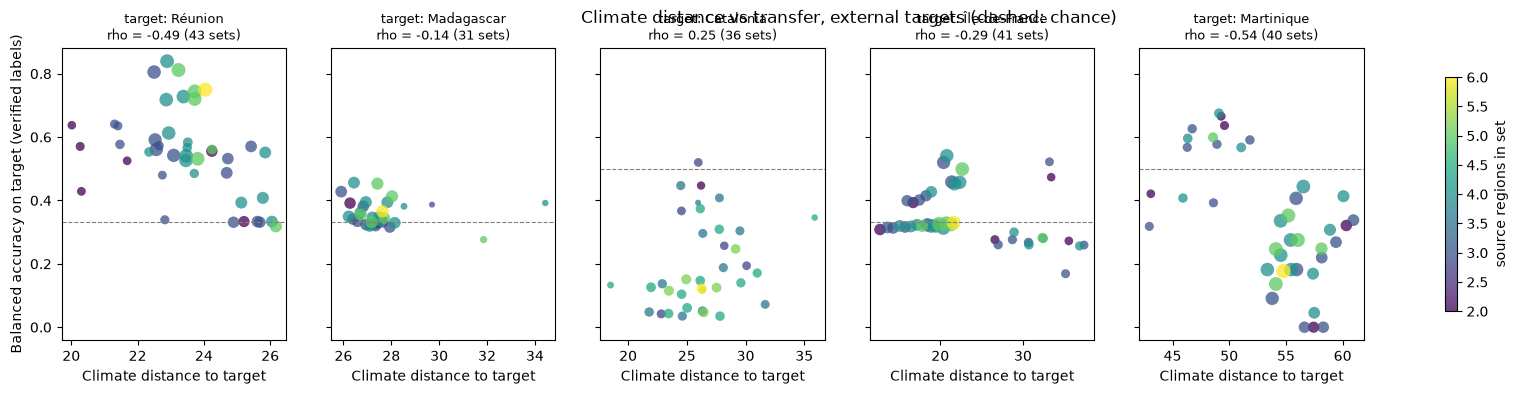

In [53]:
plots.climate_external_targets(data, TARGETS, external_sets, target_stats, FIGURES)

### 5.2 Exploratory application: Atok

The same idea applied to Atok, **for exploration only**. These scores measure agreement with undated advisor rotations on 5 field-crops, so they cannot establish whether climate similarity helps (5.1 does that). They are kept because they choose the climate-ranked training set used for the second Atok map model, and to show how the provisional labels respond.

Sets are eligible if they hold at least `MIN_PARCELS_PER_CROP` development parcels of every crop. The climate-ranked set is the smallest prefix of the climate ranking that is eligible. It is compared with all other eligible sets, and with size-matched random parcels.

In [54]:
dev_parcels = experiments.development_parcels(development, REGIONS)
eligible_sets = experiments.eligible_region_sets(dev_parcels)
print(f"Eligible region sets (>= {config.MIN_PARCELS_PER_CROP} development parcels of every crop): "
      f"{len(eligible_sets)} of {2 ** len(REGIONS) - 1}")
display(dev_parcels.assign(eligible_alone=(dev_parcels >= config.MIN_PARCELS_PER_CROP).all(axis=1)))

Eligible region sets (>= 5 development parcels of every crop): 87 of 127


crop,carrot,cabbage,potato,eligible_alone
source_region,,,,
CropHarvest: Réunion (FR),0,1,7,False
CropHarvest: Madagascar,32,2,29,False
FranceCrops: France,0,14,0,False
Sen4AgriNet: Catalonia (ES),21,0,106,False
CropHarvest: Île-de-France,3,3,4,False
CropHarvest: Martinique (FR),1,4,0,False
CropHarvest: Senegal,0,6,0,False


In [55]:
CLIMATE_SET = experiments.ranked_prefix(dev_parcels, list(distances.sort_values("climate_distance").index))
ALIGNED_SET = experiments.ranked_prefix(dev_parcels, list(distances.sort_values("aligned_distance").index))
print("Climate-ranked set (calendar months):", CLIMATE_SET)
print("Climate-ranked set (season-aligned):", ALIGNED_SET)

Climate-ranked set (calendar months): ['CropHarvest: Réunion (FR)', 'CropHarvest: Madagascar', 'FranceCrops: France']
Climate-ranked set (season-aligned): ['CropHarvest: Réunion (FR)', 'CropHarvest: Madagascar', 'FranceCrops: France']


In [56]:
region_sets = experiments.atok_region_sets(development, atok, eligible_sets, dev_parcels, distances, CLIMATE_SET, ALIGNED_SET)
region_sets.to_csv(OUTPUT / "climate_region_sets.csv", index=False)
correlations = experiments.region_set_correlations(region_sets)
correlations.to_csv(OUTPUT / "climate_correlations.csv", index=False)
display(correlations)

,distance,spearman_rho,p_value,slope_per_distance_unit (adjusted for log parcels),slope_per_log_parcels
0,calendar_distance,-0.717,5.969e-15,-0.017,-0.106
1,aligned_distance,-0.801,1.145e-20,-0.014,-0.083
2,training parcels (no climate),-0.468,4.783e-06,NaN,NaN


In [57]:
climate_rows = development[development["source_region"].isin(CLIMATE_SET)]
control_scores = experiments.size_matched_controls(development, atok, climate_rows)
climate_score = float(region_sets.loc[region_sets["is_climate_set"], "atok_balanced_acc"].iloc[0])
print(f"Climate-ranked set Atok balanced accuracy {climate_score:.3f}; size-matched random controls "
      f"{np.mean(control_scores):.3f} ± {np.std(control_scores, ddof=1):.3f} "
      f"(climate set above {np.mean(np.array(control_scores) < climate_score):.0%} of draws)")
display(region_sets.head(10))

Climate-ranked set Atok balanced accuracy 0.361; size-matched random controls 0.249 ± 0.038 (climate set above 100% of draws)


,regions,n_regions,train_parcels,calendar_distance,aligned_distance,parcels_carrot,parcels_cabbage,parcels_potato,atok_balanced_acc,atok_macro_F1,atok_OA,is_climate_set,is_aligned_set
0,CropHarvest: Madagascar + CropHarvest: Martini...,2,68,25.113,21.558,33,6,29,0.502,0.436,0.443,False,False
1,CropHarvest: Madagascar + CropHarvest: Martini...,3,74,27.876,24.609,33,12,29,0.440,0.286,0.348,False,False
2,CropHarvest: Madagascar + FranceCrops: France ...,3,83,26.336,23.423,32,22,29,0.423,0.267,0.318,False,False
3,CropHarvest: Madagascar + FranceCrops: France,2,77,23.776,20.636,32,16,29,0.422,0.268,0.316,False,False
4,CropHarvest: Madagascar + FranceCrops: France ...,3,82,25.600,22.651,33,20,29,0.413,0.243,0.295,False,False
5,CropHarvest: Madagascar + FranceCrops: France ...,4,88,27.890,25.142,33,26,29,0.411,0.239,0.294,False,False
6,CropHarvest: Réunion (FR) + CropHarvest: Madag...,3,76,24.466,21.124,33,7,36,0.404,0.346,0.356,False,False
7,CropHarvest: Madagascar + FranceCrops: France ...,5,98,28.020,25.552,36,29,33,0.398,0.244,0.293,False,False
8,CropHarvest: Madagascar + CropHarvest: Senegal,2,69,26.006,22.501,32,8,29,0.398,0.327,0.408,False,False
9,CropHarvest: Madagascar + FranceCrops: France ...,4,92,25.987,23.359,36,23,33,0.396,0.240,0.289,False,False


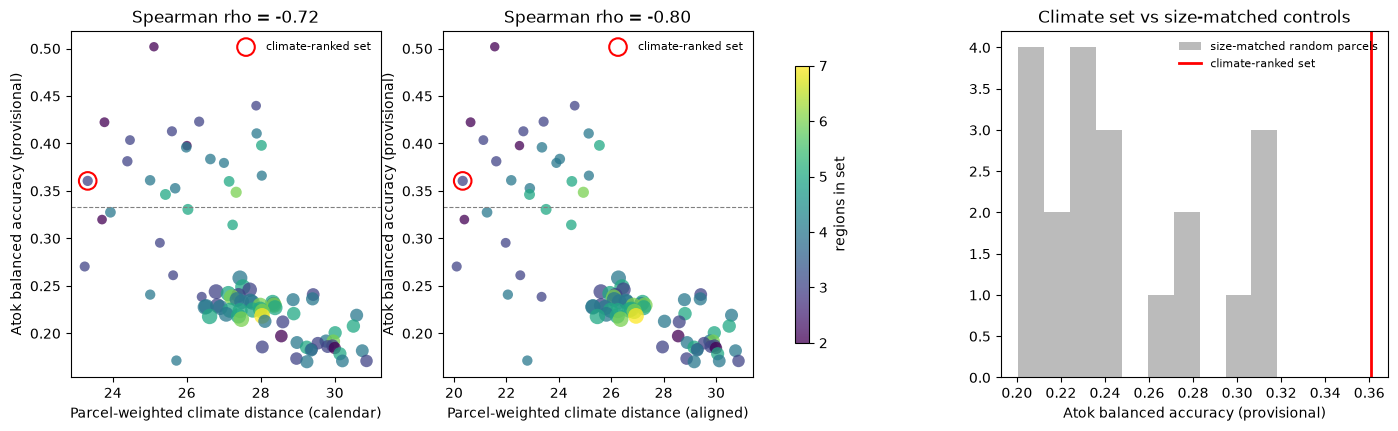

In [58]:
plots.climate_experiment(region_sets, correlations, control_scores, climate_score, FIGURES)

In [59]:
CLIMATE_LABEL = " + ".join(r.split(": ")[1] for r in CLIMATE_SET)
CLIMATE_MODEL = f"RF, interval, climate set ({CLIMATE_LABEL})"
climate_model, climate_calibrator, CLIMATE_THRESHOLD = models.calibrated_model(climate_rows, CAL_METHOD)
print(f"Climate-set model: calibrated threshold {CLIMATE_THRESHOLD}")
test_results = models.append_test_row(test_results, models.test_row(CLIMATE_MODEL, climate_model, test, INTERVAL))
test_results.to_csv(OUTPUT / "external_test_results.csv", index=False)
display(test_results.tail(1))

Climate-set model: calibrated threshold 0.34


,model,n,OA,balanced_acc,macro_F1,PA_carrot,UA_carrot,PA_cabbage,UA_cabbage,PA_potato,UA_potato,macro_F1_95CI
7,"RF, interval, climate set (Réunion (FR) + Mada...",634,0.511,0.533,0.508,0.445,0.845,0.849,0.411,0.305,0.521,0.303-0.635


**Robustness: is it climate, or one source?** Region sets overlap, so the p-values above treat 87 non-independent sets as independent. In addition, a parcel-weighted distance is dominated by whichever region contributes the most parcels. The check below compares sets with and without each region, and recomputes the correlation after dropping every set that contains that region. If the climate effect is real, the correlation should survive removing any single region.

In [60]:
robustness = experiments.drop_one_region(region_sets, REGIONS)
robustness.to_csv(OUTPUT / "climate_robustness.csv", index=False)
display(robustness)

,region,sets_with,mean_atok_balanced_acc_with,mean_without,sets_without,spearman_rho_without (aligned),p_without
0,CropHarvest: Réunion (FR),44,0.248,0.277,43,-0.875,1.597e-14
1,CropHarvest: Madagascar,60,0.292,0.196,27,-0.281,1.550e-01
2,FranceCrops: France,48,0.271,0.252,39,-0.807,5.440e-10
3,Sen4AgriNet: Catalonia (ES),57,0.214,0.354,30,0.172,3.623e-01
4,CropHarvest: Île-de-France,46,0.250,0.276,41,-0.857,8.509e-13
5,CropHarvest: Martinique (FR),47,0.270,0.254,40,-0.797,7.477e-10
6,CropHarvest: Senegal,48,0.255,0.271,39,-0.744,5.873e-08


## 6. Atok evaluation (provisional labels)

**These labels are not ground truth.** They are advisor-described, undated rotations, repeated every year. There are 2 carrot, 2 cabbage and 1 potato field. The 8,903 pixel-windows are not independent: they are repeated pixels and years of 5 field-crop combinations. Read every number below as agreement with an assumed calendar on 5 field-crops.

### 6.1 Transferred models against baselines

Carrot is the majority of the Atok samples, so **always answering carrot** is the baseline to beat on overall accuracy. On balanced accuracy, the baseline is 1/3.

In [61]:
ATOK_MODELS = {**pooled, CLIMATE_MODEL: (climate_model, INTERVAL)}
display(atok_units)
atok_results, atok_predictions = experiments.atok_evaluation(atok, ATOK_MODELS)
atok_results.to_csv(OUTPUT / "atok_transfer_results.csv", index=False)
display(atok_results)

,independent fields,fields,field-seasons (field x calendar window),field-season-years,pixel-windows (not independent),"verified (dated, field-checked) fields"
carrot,2,"Area 2, B1",2,14,5117,0
cabbage,2,"Area 2, Area 3",4,20,1306,0
potato,1,Area 2,1,7,2480,0


,model,n,OA,balanced_acc,macro_F1,PA_carrot,UA_carrot,PA_cabbage,UA_cabbage,PA_potato,UA_potato
0,Baseline: always carrot,8903,0.575,0.333,0.243,1.000,0.575,0.000,NaN,0.000,NaN
1,Baseline: guess with class shares (expected),8903,0.429,0.333,0.333,0.575,0.575,0.147,0.147,0.279,0.279
2,"RF, interval (prespecified prototype)",8903,0.204,0.218,0.185,0.130,0.421,0.127,0.122,0.396,0.165
3,"LR, interval",8903,0.270,0.320,0.255,0.262,0.499,0.570,0.198,0.126,0.128
4,"RF, shape",8903,0.268,0.220,0.208,0.298,0.458,0.030,0.055,0.334,0.170
5,"LR, shape (v1 CV-selected)",8903,0.245,0.288,0.226,0.250,0.441,0.529,0.180,0.084,0.097
6,"RF, interval (tuned by grouped CV)",8903,0.230,0.254,0.217,0.153,0.515,0.208,0.124,0.402,0.192
7,"RF, interval, climate set (Réunion (FR) + Mada...",8903,0.219,0.361,0.201,0.116,0.872,0.884,0.185,0.083,0.104


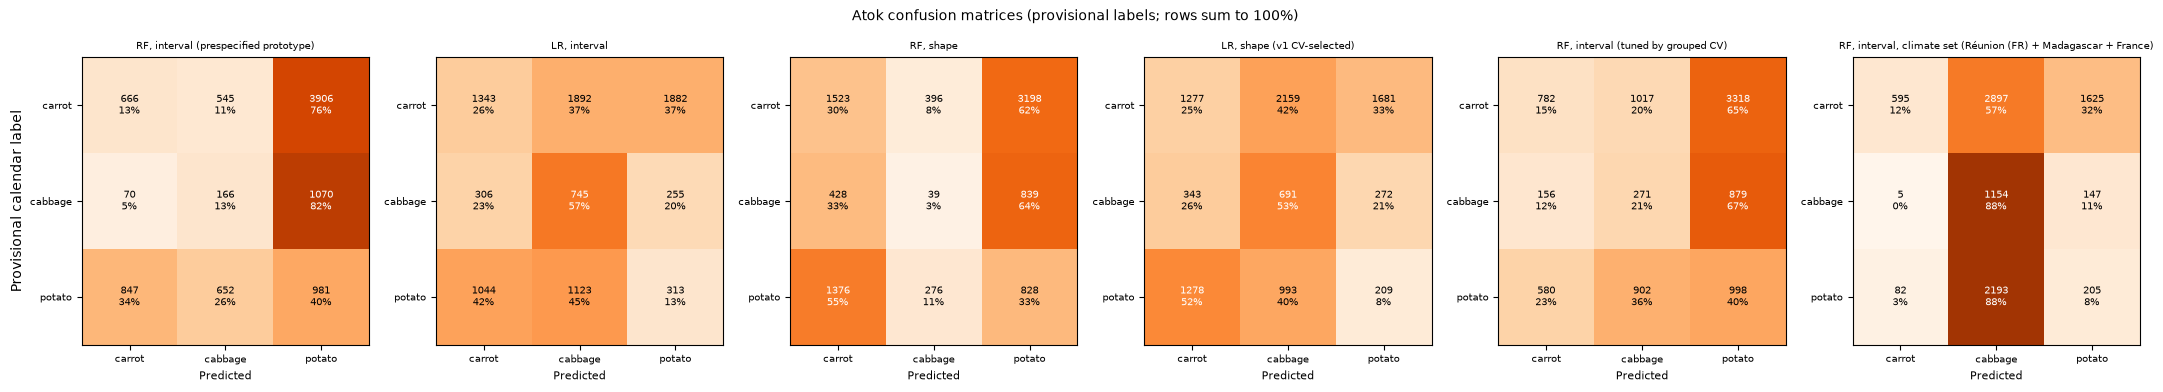

In [62]:
plots.atok_confusion_matrices(atok, atok_predictions, FIGURES)

### 6.2 Clear-data sensitivity

Atok windows may have up to 2 interpolated half-months, while the external windows are complete. The same models are rescored on Atok samples with at least 5, 6 (the default), 7 and 8 clear composites; 8 means no interpolation, matching the external data. The window length (8 half-months) cannot be varied here because the external tables were exported with 8 bins.

In [63]:
sensitivity = experiments.clear_sensitivity(atok_all, ATOK_MODELS, [PROTOTYPE, LR_SHAPE, CLIMATE_MODEL])
sensitivity.to_csv(OUTPUT / "atok_clear_sensitivity.csv", index=False)
display(experiments.sensitivity_table(sensitivity))

,"LR, shape (v1 CV-selected)","RF, interval (prespecified prototype)","RF, interval, climate set (Réunion (FR) + Madagascar + France)",n,field_season_years
min_clear,,,,,
5,0.289,0.210,0.356,10128,46
6,0.288,0.218,0.361,8903,41
7,0.260,0.198,0.326,5065,26
8,0.321,0.166,0.296,1915,14


### 6.3 Domain shift on Atok

The first panel puts Atok samples and the external development samples in the same two principal components, fitted on the external data. The second shows the share of Atok samples flagged out-of-distribution (4.6), by field and crop. A model is extrapolating whenever most of its inputs are out of distribution.

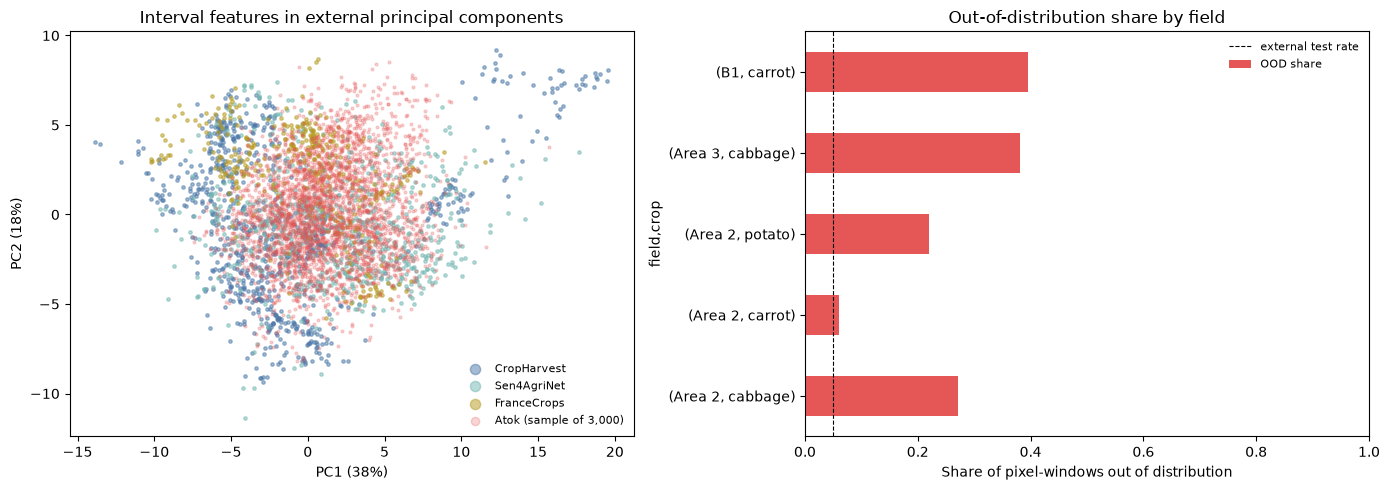

OOD share
field  crop              
Area 2 cabbage      0.272
       carrot       0.060
       potato       0.221
Area 3 cabbage      0.382
B1     carrot       0.396

In [64]:
ood_table = plots.atok_domain_shift(development, atok, distance_to_training, FIGURES)
display(ood_table)

### 6.4 Failure analysis

This finds which field, season and year combinations fail, and whether failure follows cloud cover (clear composites) or distance from the training data. Each row is one field, crop and calendar window.

In [65]:
FAILURE_MODELS = {"pooled RF": PROTOTYPE, "climate-set RF": CLIMATE_MODEL}
failure, by_window = experiments.failure_table(atok, atok_predictions, FAILURE_MODELS)
by_window.to_csv(OUTPUT / "atok_failure_by_window.csv")
display(by_window)

years  pixel_windows  median_clear  ood_share  correct_pooled RF  correct_climate-set RF
field  crop    start_month                                                                                          
Area 2 cabbage 7                3            934           6.0      0.272              0.085                   0.960
       carrot  11               7           3011           7.0      0.060              0.094                   0.161
       potato  3                7           2480           6.0      0.221              0.396                   0.083
Area 3 cabbage 3                6            121           7.0      0.364              0.579                   0.901
               7                4             76           6.0      0.329              0.066                   1.000
               11               7            175           7.0      0.417              0.069                   0.411
B1     carrot  3                7           2106           7.0      0.396              0.182                   0.052

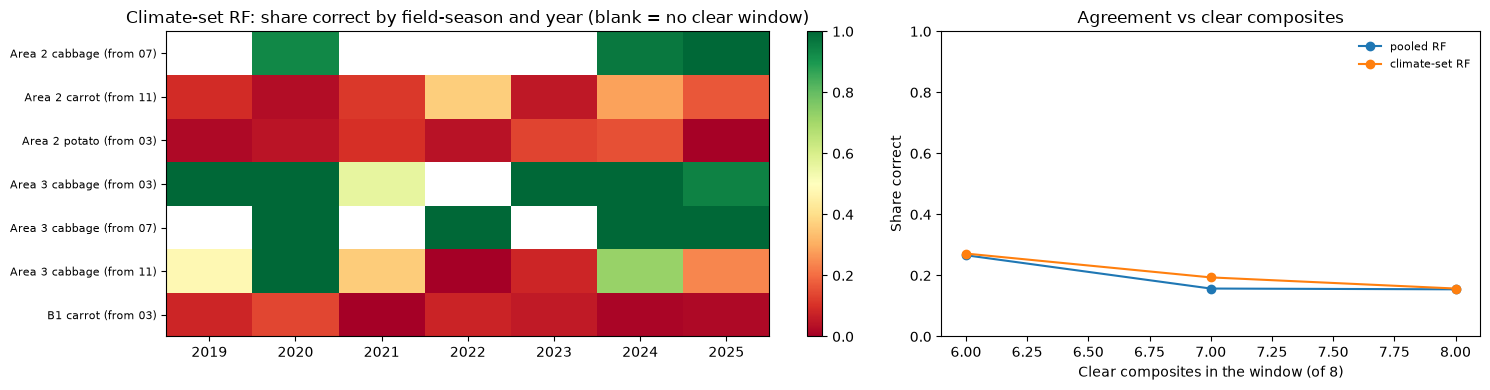

In [66]:
plots.atok_failure_analysis(failure, FAILURE_MODELS, FIGURES)

### 6.5 Weak-label fitting diagnostic (not a measure of generalisation)

**Field-independent validation is unavailable:** it needs at least 2 fields of every crop, and potato has 1. This section therefore splits field-season-years 70/30 by crop, so **the same physical fields, and the same repeated calendar assumption, appear in training and test**. It only shows whether an RF can fit the weak labels at all. It must not be quoted as accuracy, nor compared with the transferred models as if it were. The transferred models are scored on the same 30% for reference.

In [67]:
benchmark = experiments.local_benchmark(atok, ATOK_MODELS)
FIELD_SPLIT = benchmark["field_split"]
print("Labelled fields per crop:", benchmark["fields_per_crop"].to_dict(), "| field-independent split possible:", FIELD_SPLIT)
if not FIELD_SPLIT:
    print("Field-independent validation: UNAVAILABLE. The split below is a weak-label fitting diagnostic only.")

Labelled fields per crop: {'carrot': 2, 'cabbage': 2, 'potato': 1} | field-independent split possible: False
Field-independent validation: UNAVAILABLE. The split below is a weak-label fitting diagnostic only.


In [68]:
benchmark["table"].to_csv(OUTPUT / "local_benchmark.csv", index=False)
print(f"Test field-season-years: {len(benchmark['test_groups'])}; test pixel-windows per crop: {benchmark['test_crops']}")
display(benchmark["table"])

Test field-season-years: 12; test pixel-windows per crop: {'carrot': 1378, 'cabbage': 149, 'potato': 884}


,model,n,OA,balanced_acc,macro_F1,PA_carrot,UA_carrot,PA_cabbage,UA_cabbage,PA_potato,UA_potato
0,Baseline: always carrot,2411,0.572,0.333,0.242,1.000,0.572,0.000,NaN,0.000,NaN
1,Baseline: guess with class shares (expected),2411,0.465,0.333,0.333,0.572,0.572,0.062,0.062,0.367,0.367
2,Local RF: weak-label fitting diagnostic (share...,2411,0.696,0.508,0.510,0.792,0.738,0.081,0.154,0.650,0.673
3,"RF, interval (prespecified prototype) (transfe...",2411,0.242,0.251,0.205,0.146,0.407,0.208,0.056,0.398,0.258
4,"LR, interval (transferred)",2411,0.296,0.285,0.244,0.403,0.603,0.329,0.045,0.124,0.273
5,"RF, shape (transferred)",2411,0.385,0.279,0.280,0.439,0.527,0.040,0.029,0.359,0.301
6,"LR, shape (v1 CV-selected) (transferred)",2411,0.281,0.355,0.237,0.365,0.511,0.604,0.090,0.096,0.200
7,"RF, interval (tuned by grouped CV) (transferred)",2411,0.231,0.289,0.212,0.147,0.494,0.383,0.063,0.336,0.270
8,"RF, interval, climate set (Réunion (FR) + Mada...",2411,0.138,0.261,0.143,0.099,0.878,0.557,0.047,0.127,0.232


## 7. Atok maps (exploratory)

These maps show what the models would produce, **not verified crop locations**. Two models are mapped: the prespecified pooled RF and the climate-set RF (section 5). Each is shown for the best- and the worst-coverage year, in the three calendar windows. Prediction is limited to the ELUM CY-2023 Crops mask. A pixel is labelled **unknown** when its top-class probability is below the abstention threshold from 4.6, or when it is out of distribution. Otherwise it gets one of the three crops, which may be wrong for any other crop or fallow land. GeoTIFFs: band 1 is the class code (1 carrot, 2 cabbage, 3 potato, 4 unknown), band 2 the top-class probability (uncalibrated for Atok), band 3 the distance to the training data.

### Cropland mask

The mask is the NAMRIA ELUM CY-2023 **Crops** polygons within the ROI. It is compared with notebook 09's unsupervised active-cropland map when that map is available.

In [69]:
cropland = atok_data.cropland_mask(roi, paths.landuse)
print(f"ELUM 2023 Crops: {cropland.sum():,} of {roi.roi_mask.sum():,} ROI pixels ({cropland.sum() / roi.roi_mask.sum():.0%}); "
      f"{cropland.sum() * 0.01:,.0f} ha")
activity = atok_data.compare_land_activity(roi, cropland, paths.land_activity)
if activity:
    print(f"Notebook 09 calls {activity['elum_crops_active']:.0%} of the ELUM Crops pixels active cropland; "
          f"{activity['active_inside_elum_crops']:.0%} of its active cropland lies inside ELUM Crops")

ELUM 2023 Crops: 29,437 of 41,115 ROI pixels (72%); 294 ha
Notebook 09 calls 67% of the ELUM Crops pixels active cropland; 94% of its active cropland lies inside ELUM Crops


In [70]:
mappable = maps.mappable_share(roi, cropland)
BEST_YEAR, WORST_YEAR = int(mappable["mean"].idxmax()), int(mappable["mean"].idxmin())
print(f"Share of the cropland mask with >= {MIN_CLEAR} of 8 clear composites:")
display(mappable.style.format("{:.0%}"))
print(f"Best-coverage year {BEST_YEAR}, worst {WORST_YEAR}")

Share of the cropland mask with >= 6 of 8 clear composites:


,Mar-Jun (potato season),Jul-Oct (cabbage season),Nov-Feb (carrot season),mean
year,,,,
2019,82%,0%,90%,58%
2020,57%,59%,43%,53%
2021,83%,2%,90%,58%
2022,71%,8%,90%,57%
2023,60%,4%,90%,51%
2024,90%,47%,90%,76%
2025,60%,28%,90%,60%


Best-coverage year 2024, worst 2023


In [71]:
MAP_MODELS = {  # name -> (file slug, calibrated model, calibrated threshold)
    "Pooled RF (prespecified prototype)": (
        "pooled_rf", models.Calibrated(pooled[PROTOTYPE][0], calibration_fit["calibrator"]), calibration_fit["threshold"]),
    f"Climate-set RF ({CLIMATE_LABEL})": (
        "climate_set_rf", models.Calibrated(climate_model, climate_calibrator), CLIMATE_THRESHOLD),
}
predictor = maps.MapPredictor(roi, cropland, distance_to_training, OOD_THRESHOLD)
map_raw, map_summary = maps.predict_maps(predictor, MAP_MODELS, (BEST_YEAR, WORST_YEAR), OUTPUT)  # also writes GeoTIFFs
background = plots.map_background(roi, cropland, maps.never_clear(roi))

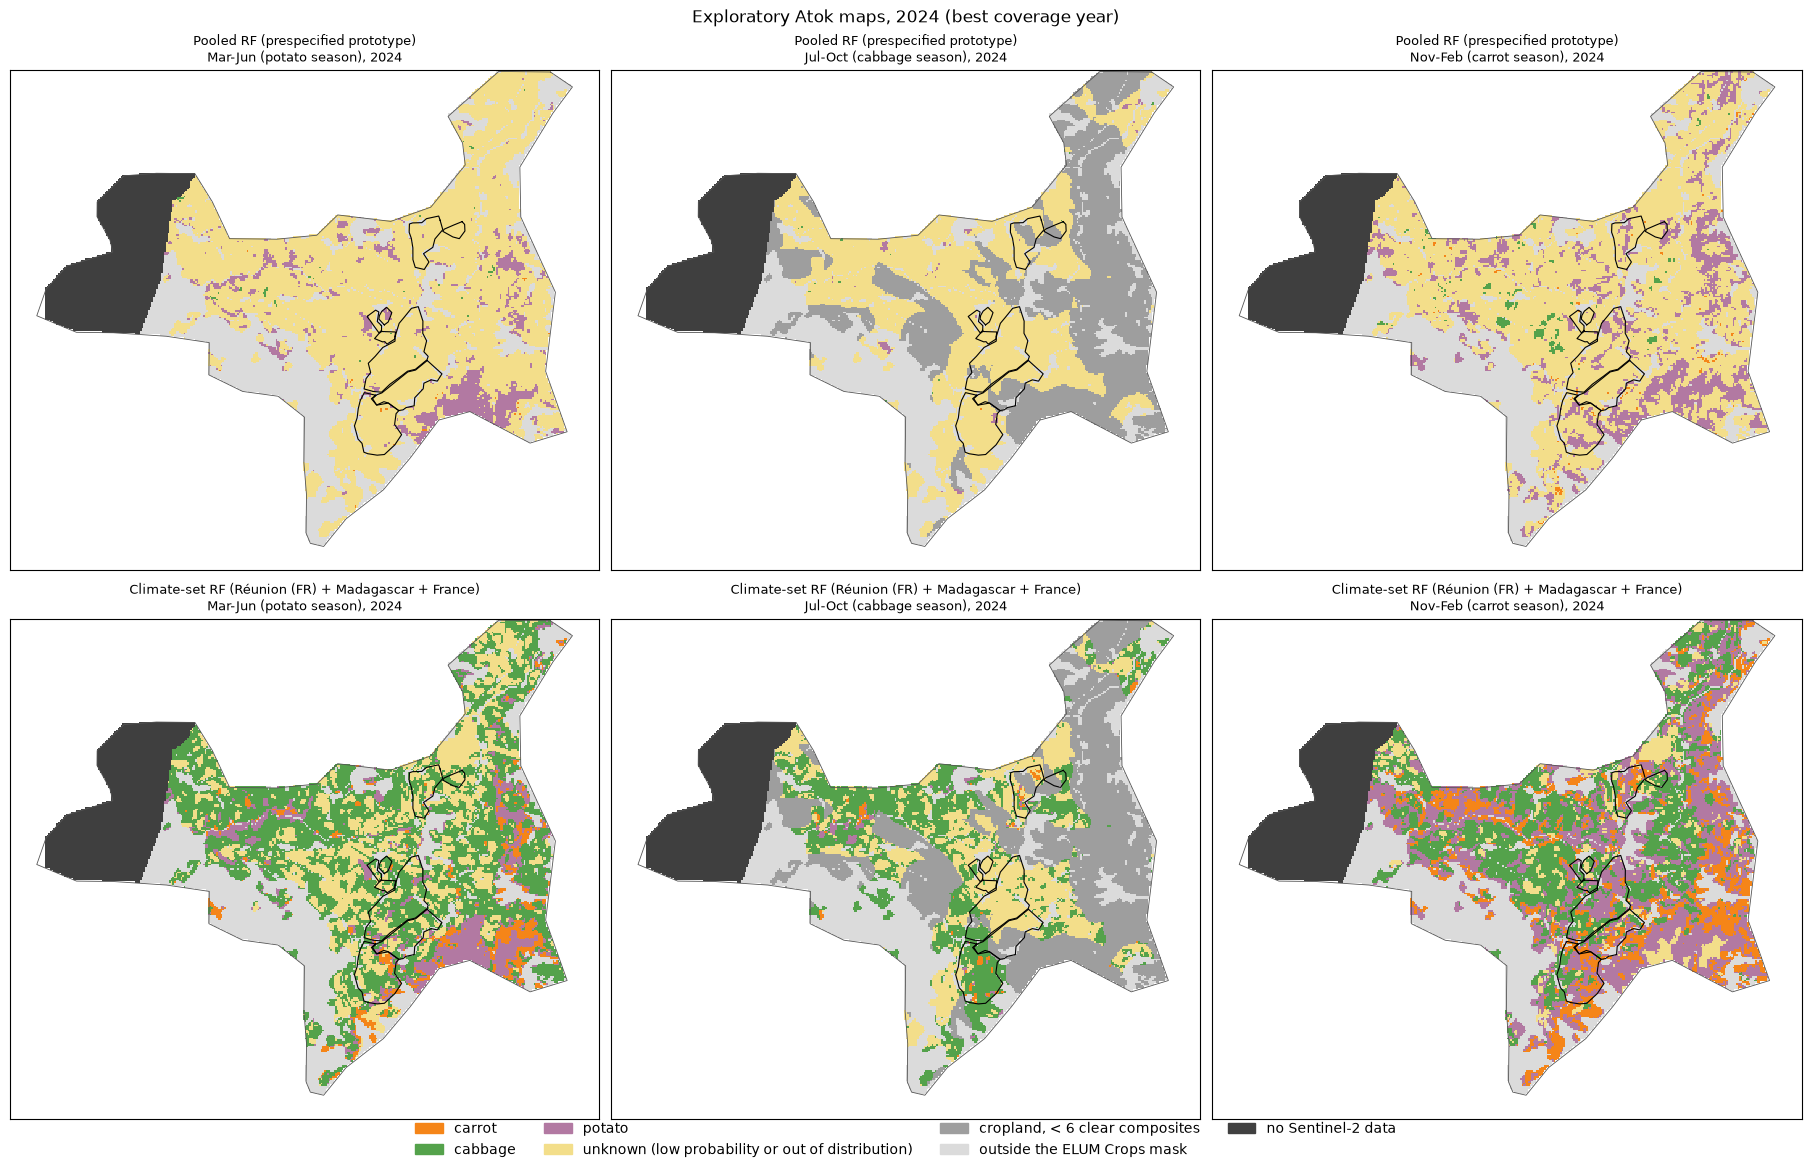

In [72]:
plots.crop_maps(map_raw, MAP_MODELS, BEST_YEAR, BEST_YEAR, roi, background, FIGURES)

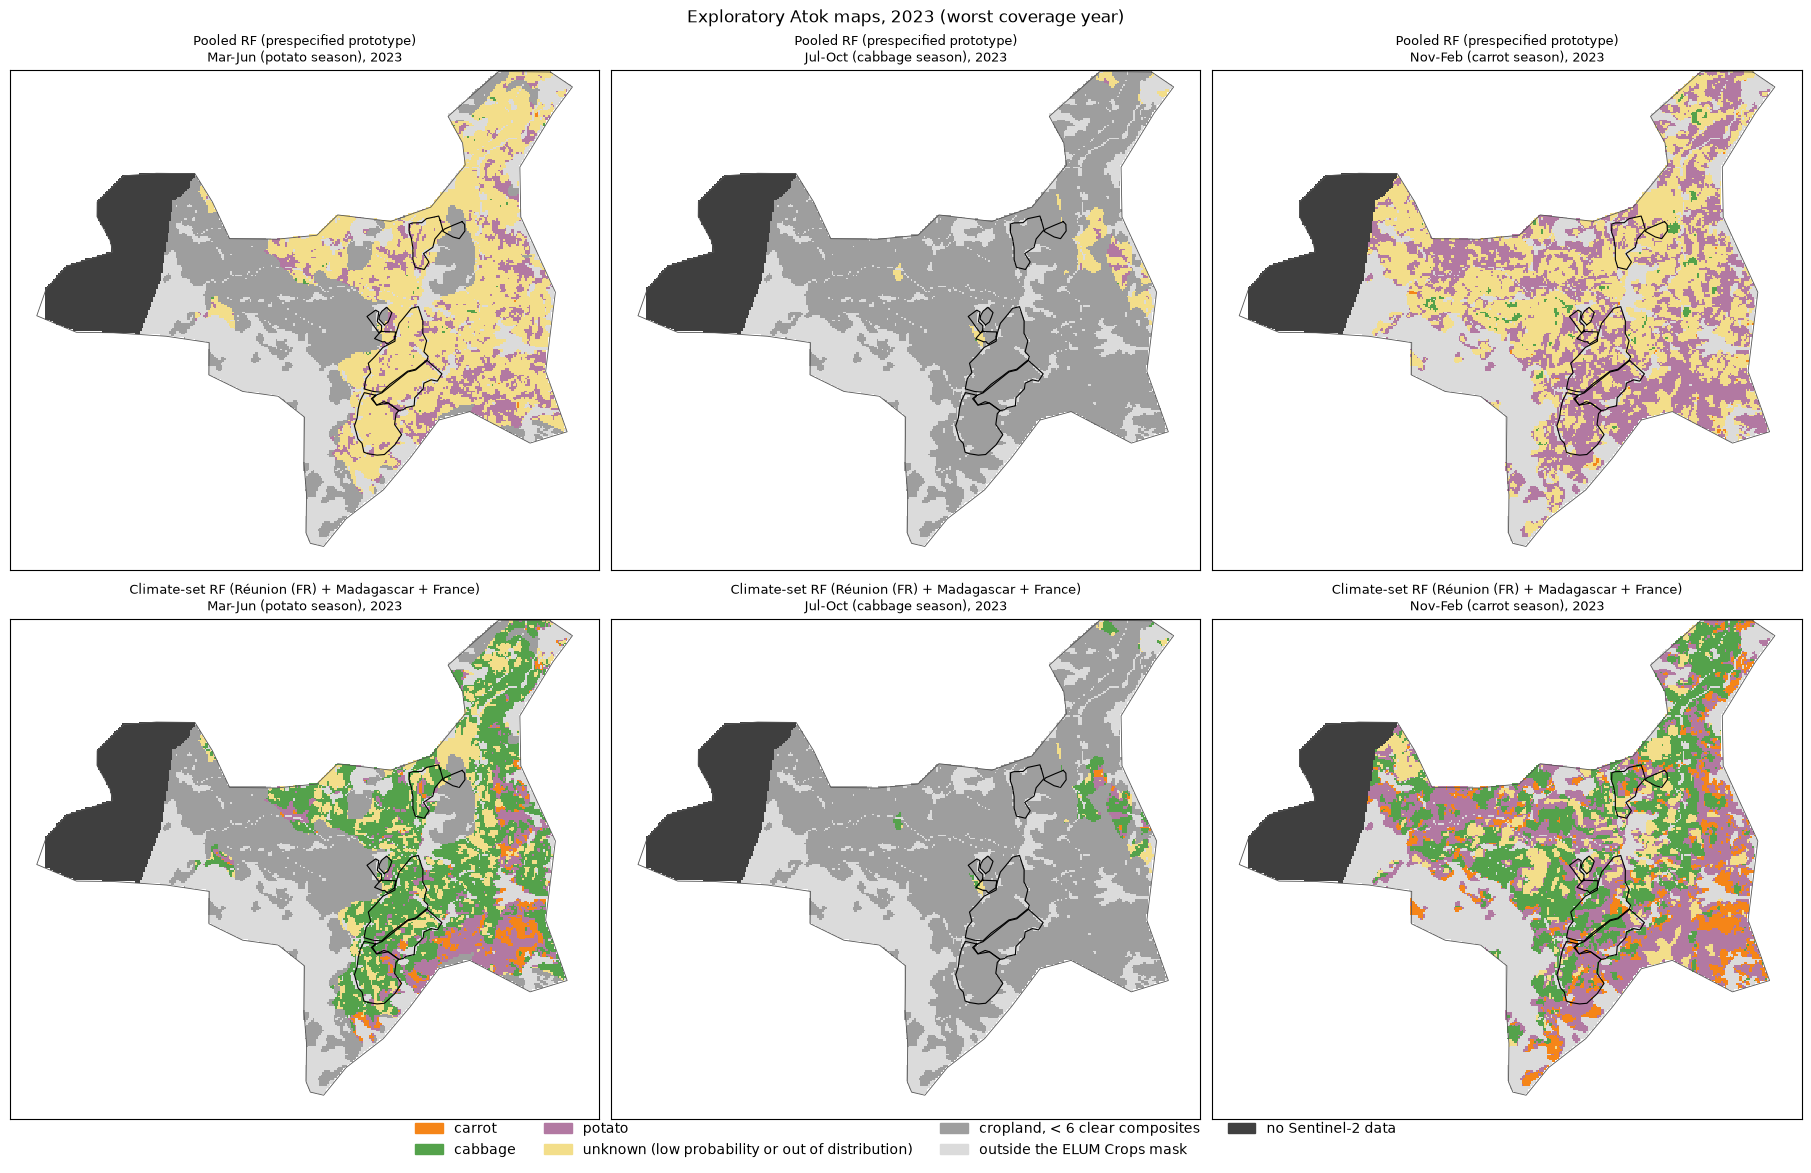

In [73]:
plots.crop_maps(map_raw, MAP_MODELS, WORST_YEAR, BEST_YEAR, roi, background, FIGURES)

In [74]:
map_summary.to_csv(OUTPUT / "atok_map_summary.csv", index=False)
display(map_summary)

,model,year,window,mapped_share_of_mask,threshold,unknown_share_of_mapped,uncertain_share_of_mapped,ood_share_of_mapped,share_carrot_of_known,share_cabbage_of_known,share_potato_of_known
0,Pooled RF (prespecified prototype),2024,Mar-Jun (potato season),0.905,0.66,0.895,8.860e-01,0.294,0.010,0.021,0.968
1,Pooled RF (prespecified prototype),2024,Jul-Oct (cabbage season),0.475,0.66,0.988,9.843e-01,0.485,0.006,0.136,0.858
2,Pooled RF (prespecified prototype),2024,Nov-Feb (carrot season),0.905,0.66,0.782,7.641e-01,0.095,0.023,0.060,0.917
3,Climate-set RF (Réunion (FR) + Madagascar + Fr...,2024,Mar-Jun (potato season),0.905,0.34,0.294,3.380e-04,0.294,0.088,0.743,0.169
4,Climate-set RF (Réunion (FR) + Madagascar + Fr...,2024,Jul-Oct (cabbage season),0.475,0.34,0.486,7.872e-04,0.485,0.033,0.930,0.036
5,Climate-set RF (Réunion (FR) + Madagascar + Fr...,2024,Nov-Feb (carrot season),0.905,0.34,0.096,1.089e-03,0.095,0.204,0.372,0.423
6,Pooled RF (prespecified prototype),2023,Mar-Jun (potato season),0.598,0.66,0.790,7.687e-01,0.203,0.003,0.016,0.981
7,Pooled RF (prespecified prototype),2023,Jul-Oct (cabbage season),0.040,0.66,0.857,8.443e-01,0.202,0.000,0.012,0.988
8,Pooled RF (prespecified prototype),2023,Nov-Feb (carrot season),0.905,0.66,0.536,4.918e-01,0.139,0.005,0.034,0.961
9,Climate-set RF (Réunion (FR) + Madagascar + Fr...,2023,Mar-Jun (potato season),0.598,0.34,0.203,1.705e-04,0.203,0.074,0.712,0.214


### 7.0 Why pixels are rejected, and what coverage a threshold would give

Two separate mechanisms make a pixel **unknown**:

- **uncertainty:** the calibrated top-class probability is below the model's threshold (4.6b);
- **out of distribution:** the pixel's features are farther from the training data than 95% of the external test samples.

The first table and maps split every rejected pixel into *uncertain only*, *out of distribution only* or *both*, for the best-coverage year. The operating-point curves show how much of the mappable cropland would be classified at other thresholds, with and without the out-of-distribution check. The proposed **minimum coverage requirement** is 50% of mappable cropland per window. The threshold behind these maps was set on external data, and 4.6b tests whether it holds in unseen regions; Atok cannot be checked without verified labels.

In [75]:
rejection_causes, cause_masks = maps.rejection_causes(map_raw, MAP_MODELS, BEST_YEAR)
rejection_causes.to_csv(OUTPUT / "atok_rejection_causes.csv", index=False)
display(rejection_causes)

,model,window,threshold,mapped_pixels,classified,uncertain only,out of distribution only,both
0,Pooled RF (prespecified prototype),Mar-Jun (potato season),0.66,26631,0.105,6.016e-01,0.009,2.845e-01
1,Pooled RF (prespecified prototype),Jul-Oct (cabbage season),0.66,13973,0.012,5.032e-01,0.004,4.811e-01
2,Pooled RF (prespecified prototype),Nov-Feb (carrot season),0.66,26629,0.218,6.872e-01,0.018,7.687e-02
3,Climate-set RF (Réunion (FR) + Madagascar + Fr...,Mar-Jun (potato season),0.34,26631,0.706,2.629e-04,0.294,7.510e-05
4,Climate-set RF (Réunion (FR) + Madagascar + Fr...,Jul-Oct (cabbage season),0.34,13973,0.514,5.725e-04,0.485,2.147e-04
5,Climate-set RF (Réunion (FR) + Madagascar + Fr...,Nov-Feb (carrot season),0.34,26629,0.904,8.637e-04,0.095,2.253e-04


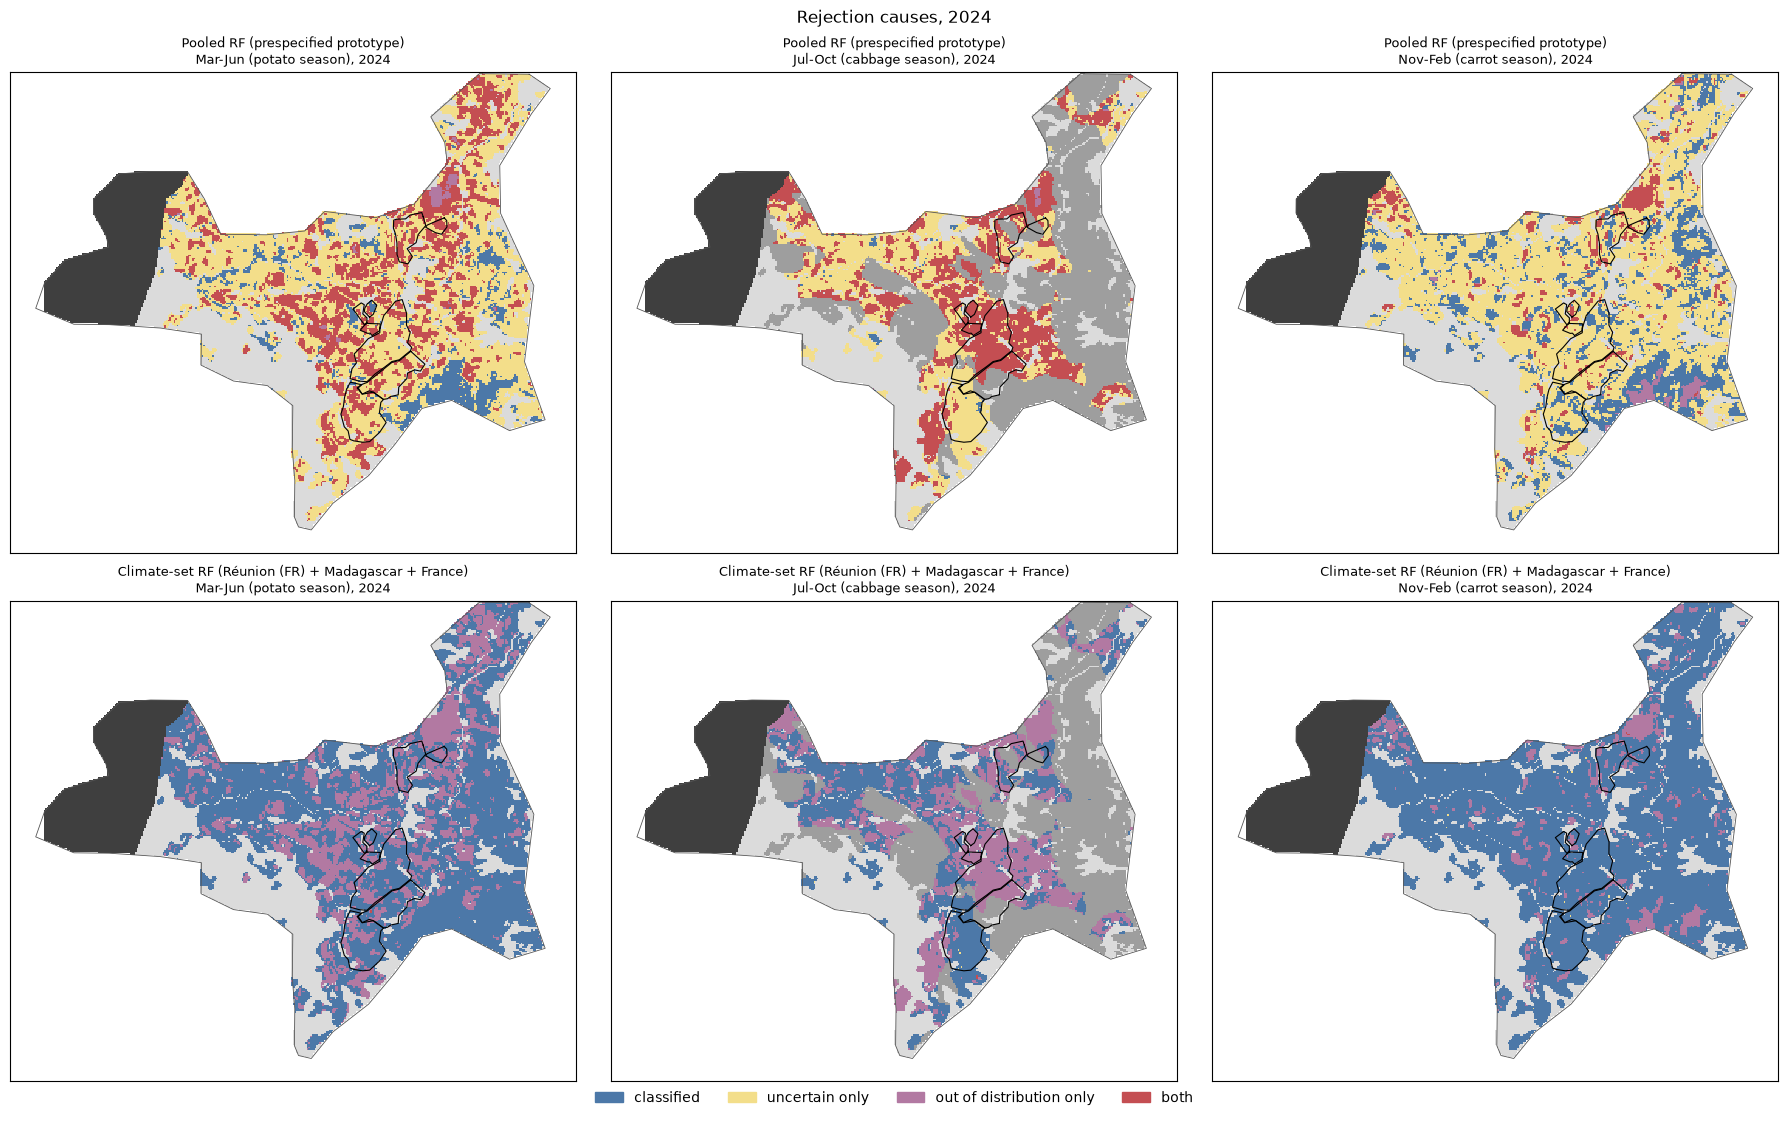

In [76]:
plots.rejection_cause_maps(cause_masks, MAP_MODELS, BEST_YEAR, roi, background, FIGURES)

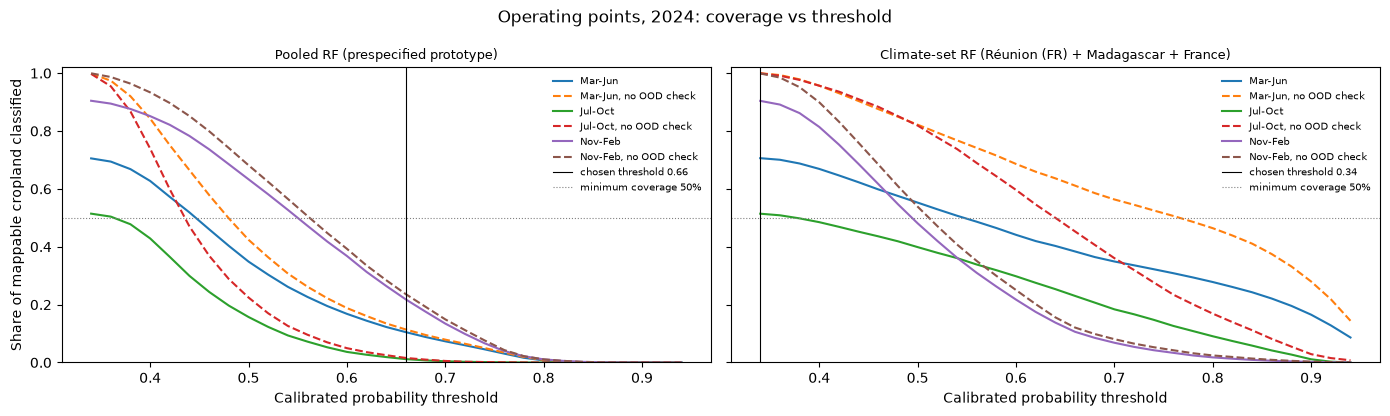

In [77]:
operating = maps.operating_points(map_raw, MAP_MODELS, BEST_YEAR)
operating.to_csv(OUTPUT / "atok_operating_points.csv", index=False)
plots.operating_points(operating, MAP_MODELS, BEST_YEAR, FIGURES)

### 7.1 Where the two models disagree

For the best-coverage year: green where both models give the same crop, red where they give different crops, yellow where either says unknown. The transition tables give pixel counts, not shares.

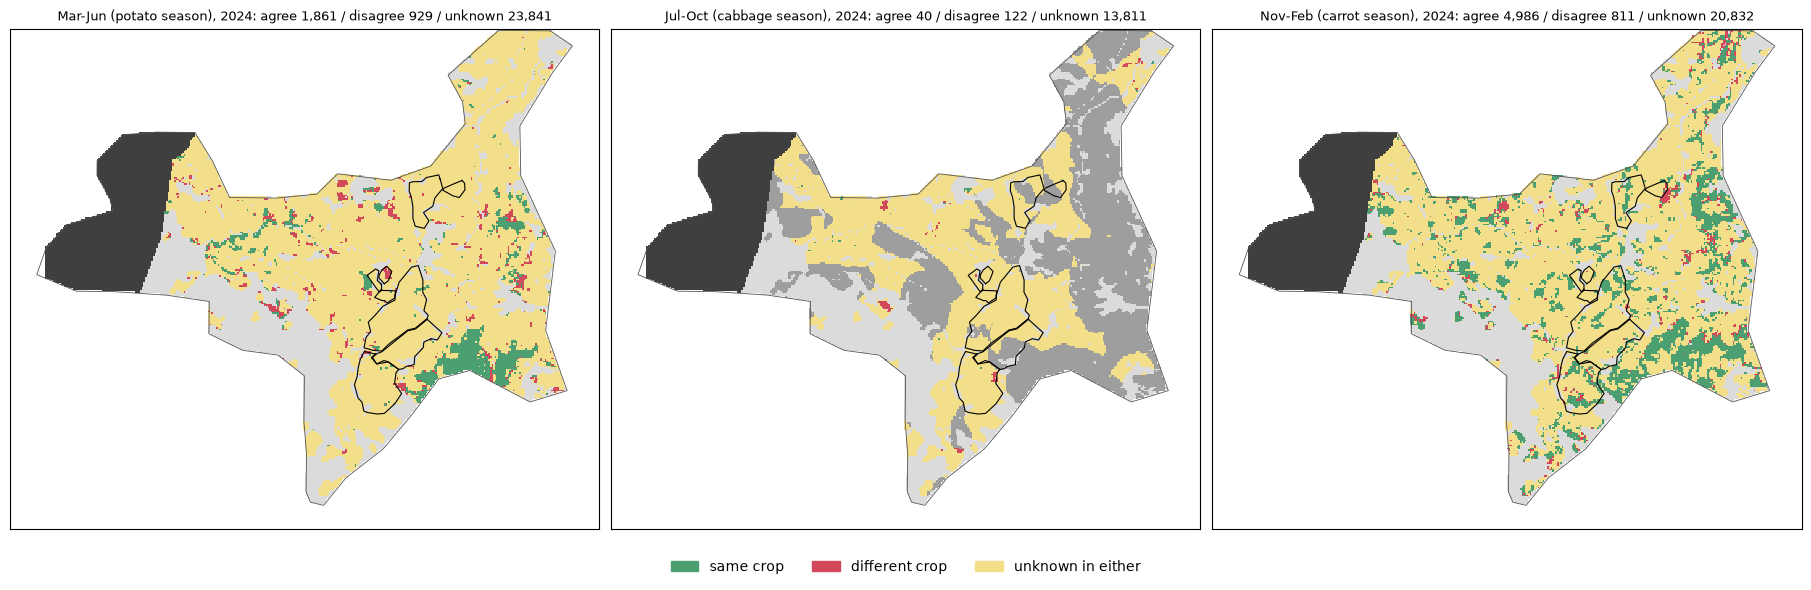

In [78]:
agreement, transitions, agreement_masks = maps.model_agreement(map_raw, MAP_MODELS, BEST_YEAR)
plots.model_disagreement(agreement_masks, BEST_YEAR, roi, background, FIGURES)

In [79]:
agreement.to_csv(OUTPUT / "atok_map_agreement.csv", index=False)
display(agreement)
for window, table in transitions:
    print(window)
    display(table)

,window,pixels_both_mapped,agree,disagree,either_unknown,agree_share_of_known
0,Mar-Jun (potato season),26631,1861,929,23841,0.667
1,Jul-Oct (cabbage season),13973,40,122,13811,0.247
2,Nov-Feb (carrot season),26629,4986,811,20832,0.860


Mar-Jun (potato season)


Climate-set RF (Réunion (FR) + Madagascar + France),cabbage,carrot,potato,unknown
Pooled RF (prespecified prototype),,,,
cabbage,59,0,0,0
carrot,4,23,2,0
potato,832,91,1779,1
unknown,13075,1537,1402,7826


Jul-Oct (cabbage season)


Climate-set RF (Réunion (FR) + Madagascar + France),cabbage,carrot,potato,unknown
Pooled RF (prespecified prototype),,,,
cabbage,22,0,0,0
carrot,0,1,0,0
potato,121,1,17,0
unknown,6541,238,244,6788


Nov-Feb (carrot season)


Climate-set RF (Réunion (FR) + Madagascar + France),cabbage,carrot,potato,unknown
Pooled RF (prespecified prototype),,,,
cabbage,346,0,0,0
carrot,0,136,0,0
potato,419,392,4504,3
unknown,8195,4395,5689,2550


### 7.2 Where the models are wrong on the labelled fields

**No verified crop polygons exist yet.** These maps zoom in on the provisional KML fields (B1, Area 2, Area 3) and score every interior pixel against the calendar crop for that window. Each pixel falls in one category:

- **correct** (blue): the model gives the calendar crop;
- **wrong crop:** the model gives a different crop, with the colour of the crop it predicted;
- **unknown:** abstained (low probability or out of distribution);
- **too cloudy:** fewer than 6 of 8 clear composites.

The first figure shows the best-coverage year, one column per calendar window. The second shows each pixel's share of correct windows across all years 2019-2025 (only windows where it was clear enough), which tells apart consistent failures from one-off ones. Once verified polygons are digitised, they replace the calendar labels here.

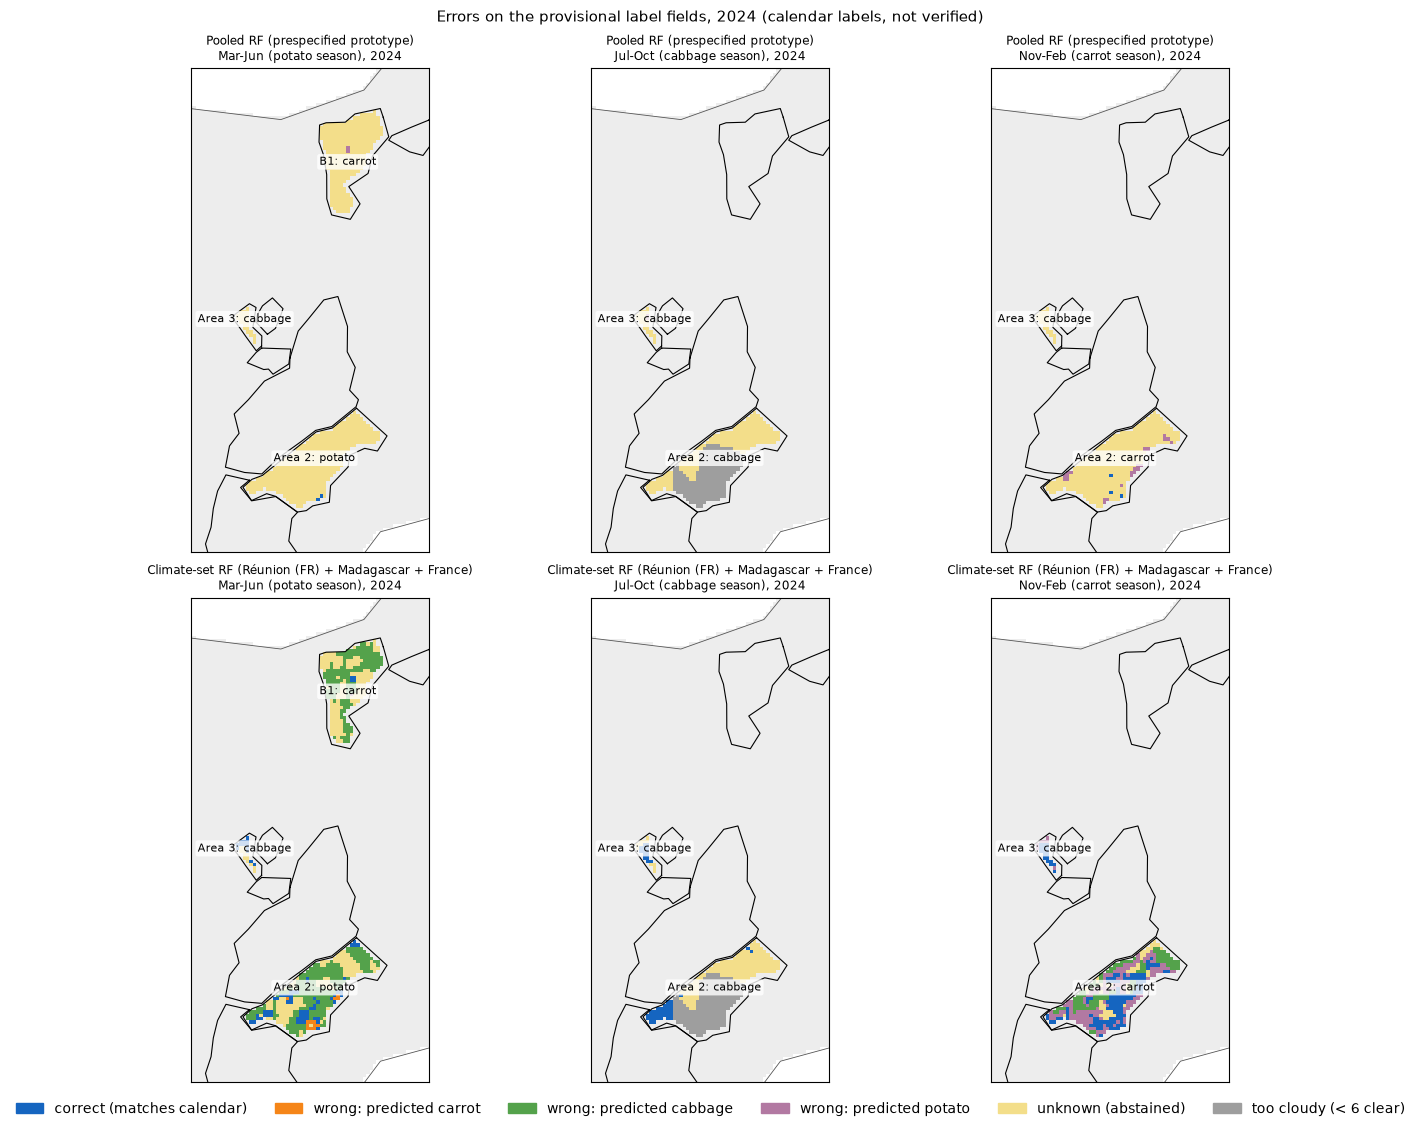

In [80]:
called, unknown = maps.labelled_field_calls(atok, MAP_MODELS)  # same calibrated models and thresholds as the maps
field_errors = maps.field_errors(atok, called, unknown, BEST_YEAR)
plots.field_errors(atok, called, unknown, BEST_YEAR, roi, maps.labelled_fields(), FIGURES)

In [81]:
field_errors.to_csv(OUTPUT / f"atok_field_errors_{BEST_YEAR}.csv", index=False)
display(field_errors)

,model,window,field,calendar_crop,pixels,correct,unknown,wrong_as_carrot,wrong_as_cabbage,wrong_as_potato
0,Pooled RF (prespecified prototype),Mar-Jun (potato season),Area 2,potato,442,0.005,0.995,0.000,0.000,0.000
1,Pooled RF (prespecified prototype),Mar-Jun (potato season),Area 3,cabbage,25,0.000,1.000,0.000,0.000,0.000
2,Pooled RF (prespecified prototype),Mar-Jun (potato season),B1,carrot,312,0.000,0.994,0.000,0.000,0.006
3,Pooled RF (prespecified prototype),Jul-Oct (cabbage season),Area 2,cabbage,212,0.000,1.000,0.000,0.000,0.000
4,Pooled RF (prespecified prototype),Jul-Oct (cabbage season),Area 3,cabbage,25,0.000,0.920,0.000,0.000,0.080
5,Pooled RF (prespecified prototype),Nov-Feb (carrot season),Area 2,carrot,442,0.007,0.941,0.000,0.000,0.052
6,Pooled RF (prespecified prototype),Nov-Feb (carrot season),Area 3,cabbage,25,0.000,1.000,0.000,0.000,0.000
7,Climate-set RF (Réunion (FR) + Madagascar + Fr...,Mar-Jun (potato season),Area 2,potato,442,0.131,0.299,0.029,0.541,0.000
8,Climate-set RF (Réunion (FR) + Madagascar + Fr...,Mar-Jun (potato season),Area 3,cabbage,25,0.520,0.480,0.000,0.000,0.000
9,Climate-set RF (Réunion (FR) + Madagascar + Fr...,Mar-Jun (potato season),B1,carrot,312,0.013,0.474,0.000,0.510,0.003


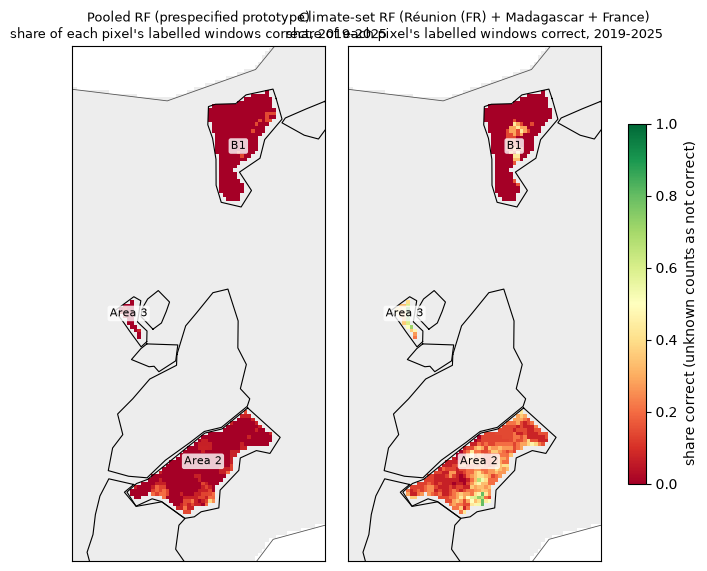

,model,pixels,median_windows_per_pixel,never_correct,always_correct,mean_share
0,Pooled RF (prespecified prototype),779,14.0,0.838,0.0,0.017
1,Climate-set RF (Réunion (FR) + Madagascar + Fr...,779,14.0,0.354,0.0,0.144


In [82]:
per_pixel_shares, consistency = maps.field_consistency(atok, called, unknown)
plots.field_consistency(per_pixel_shares, roi, maps.labelled_fields(), FIGURES)
consistency.to_csv(OUTPUT / "atok_field_consistency.csv", index=False)
display(consistency)

## 8. Limitations and requirements (Obj 4)

Each limitation has an evidence number computed in this notebook (or read from v1), the requirement that would address it, and a priority.

In [83]:
v1_transfer = json.loads((paths.v1 / "transfer_metrics.json").read_text())
results = {  # evidence for the limitations, criteria and summary tables
    "atok": atok, "atok_units": atok_units, "grid": roi, "cropland": cropland, "atok_results": atok_results,
    "month_clear": month_clear, "mappable": mappable, "best_year": BEST_YEAR, "worst_year": WORST_YEAR,
    "test_results": test_results, "test_parcels": test["partition_group"].nunique(),
    "grid_table": tuning, "prototype_gap": tuning.loc[tuning["prototype"], "gap"].iloc[0], "tuned_params": TUNED_PARAMS,
    "calibration": calibration_fit, "abstention": abstention, "threshold_transfer": threshold_transfer,
    "rejection_causes": rejection_causes, "target_stats": target_stats, "agreement": agreement,
    "france_accuracy": v1_transfer["france_to_cropharvest"]["by_region"]["France"]["accuracy"],
    "pagasa_elevation_m": paths.pagasa_elevation_m, "field_split": FIELD_SPLIT,
    "target_note": climate_profiles.note, "climate_set": CLIMATE_SET, "aligned_set": ALIGNED_SET,
    "eligible_sets": len(eligible_sets), "correlations": correlations, "climate_score": climate_score,
    "control_scores": control_scores, "map_models": MAP_MODELS, "ood_threshold": OOD_THRESHOLD,
}

In [84]:
limitations = report.limitations(results)
limitations.to_csv(OUTPUT / "limitations_requirements.csv", index=False)
display(limitations.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,limitation,evidence,requirement,priority
0,Atok labels are not ground truth,undated advisor rotations repeated 2019-2025; 0 verified fields,"Dated, field-checked crop observations per plot and season, kept separate from calendar labels",Critical
1,Too few independent Atok fields,"carrot: 2; cabbage: 2; potato: 1 fields (8,903 pixel-windows, not independent)",At least 5 verified fields per crop; report fields and field-seasons as the sample size,Critical
2,No field-independent Atok holdout,potato in 1 field; local benchmark shares fields between train and test,Field-independent holdout with >= 2 test fields per crop,Critical
3,Majority baseline beats the models on Atok OA,"always-carrot OA 0.57; best model by balanced accuracy (RF, interval, climate set (Réunion (FR) + Madagascar + France)) OA 0.22, balanced acc 0.36","Report balanced accuracy, per-crop recall and baselines; judge models by the acceptance criteria (9)",High
4,Source confound,"France -> CropHarvest: CropHarvest France rows score 0.232 accuracy (v1), same country and climate, different source",Cross-source coverage for every crop; test source harmonisation separately from climate,High
5,Overfitting / source shift,prototype train-validation macro-F1 gap 0.46 in grouped CV; best tuned gap 0.21,More parcels per crop and source; stricter (region-level) validation; source-balanced training (4.3),High
6,Small external test,"prototype test macro-F1 0.581 (95% parcel CI 0.403-0.704), 58 test parcels",More parcels; repeated grouped splits,High
7,Domain shift to Atok,22% of Atok pixel-windows out of distribution (vs 5% of external test),Training data from comparable highland systems; local labelled data,High
8,May-Aug cloud gap,"47% of ROI half-months clear in May-Aug vs 72% otherwise; 47% of cropland mappable Jul-Oct even in 2024, 4% in 2023",Add Sentinel-1 SAR (VV/VH),High
9,Map instability,pooled vs climate-set RF agree on 25%-86% of known pixels (2024),Verified labels to decide between models; report disagreement maps with every map,High


## 9. Pilot acceptance criteria (proposed)

These criteria are proposed **for the verified pilot**: fix them before that evaluation, not after. They are shown against the current provisional results only to make the gap explicit. A model would count as a working Atok classifier only if it meets every row on verified, field-independent data.

The pilot also needs things this notebook cannot provide:

- **Representative sampling:** plots across elevation, slope, aspect, field size and mixed cropping.
- **An end-to-end run:** imagery ingestion → inference → map → interpretation by agricultural staff.
- **A failure analysis on verified fields:** clouds, phenology, shadows, crop similarity and label quality.

In [85]:
criteria = report.acceptance_criteria(results)
criteria.to_csv(OUTPUT / "acceptance_criteria.csv", index=False)
display(criteria)
print(f"Criteria met: {int(criteria['met'].sum())} of {len(criteria)}")

,criterion,target,"current (best provisional model: RF, interval, climate set (Réunion (FR) + Madagascar + France))",met
0,Verified independent fields per crop,>= 5,"0 verified (provisional fields: carrot 2, cabb...",False
1,Field-independent holdout,"yes, >= 2 test fields per crop",no,False
2,Per-crop recall (producer's accuracy),>= 0.60 for every crop,min 0.08,False
3,Per-crop precision (user's accuracy),>= 0.60 for every crop,min 0.10,False
4,Macro-F1,>= 0.60,0.20,False
5,Balanced accuracy,>= 0.53 (chance + 0.20),0.36,False
6,Overall accuracy above the majority baseline,> 0.57 + 0.10,0.22,False
7,Classified share of mappable cropland,">= 50% in every window, at a threshold validat...",not assessable (no verified labels); at extern...,False
8,Abstention threshold transfers to unseen regions,>= 70% kept accuracy in >= 80% of held-out reg...,1 of 7 regions,False
9,Mappable cropland per season,>= 70% in every window,min 47% (2024),False


Criteria met: 0 of 12


## Summary

From the run on 2026-11-09 (PAGASA Baguio target, lapse-adjusted −4.9 °C to 2,255 m). **This is an exploratory feasibility study. None of the 12 proposed pilot acceptance criteria (section 9) is met, and 2 (map coverage and Atok calibration) cannot even be assessed without verified Atok labels: there are 0 verified fields, and only 2 carrot, 2 cabbage and 1 potato provisional fields.** Field-independent validation is unavailable.

**External data (verified labels)**
- **Same predictors, different classifiers (4.1, 4.2):** interval predictors beat shape predictors for both models. On the locked test set, LR on interval predictors scores macro-F1 0.657 (95% CI 0.475-0.776) against 0.581 (0.403-0.704) for the prespecified RF; v1's CV gave the same order. The prototype stays prespecified. The intervals overlap widely.
- **Overfitting (4.3, 4.4):** the prototype's grouped-CV gap is 0.46 (training 0.98, validation 0.52). A minimum leaf of 25 cuts the gap to 0.21 at the same validation score (0.53), so the gap is memorisation, not useful fit. Source-balanced weights add ≤ 0.01. Validation flattens at about 0.52, and carrot recall stays near 0.25 at every training size.
- **Calibration (4.6, 4.6b):** the raw RF probabilities are already fairly well calibrated (ECE 0.039 out of fold, 0.081 on test). Temperature scaling (0.063) and matrix scaling (0.082) were both fitted and cross-validated, and both made calibration worse, so the raw probabilities are kept. The abstention threshold (0.66) keeps 33% of test predictions at 84% accuracy.
- **Threshold transfer (4.6b):** set on the other regions and applied to an unseen one, the threshold reaches 70% kept accuracy in **1 of 7** regions (Réunion). Elsewhere, kept accuracy is 0-28%. **A threshold set on external data does not carry over to a new region, so the one used for Atok has no validated meaning there.**
- **New regions (4.7):** leave-one-region-out balanced accuracy is 0.12-0.35 for most regions (0.75 for Réunion). On the comparable one-vs-rest measure (AUC, chance 0.5), single-region transfer averages 0.51 for carrot, 0.60 for cabbage and 0.60 for potato on external targets. On Atok it is 0.36-0.41, **below chance** for all three crops.

**Climate matching (5)**
- **Primary test, external targets with verified labels (5.1):** across 5 target regions, the climate-distance correlation is negative in 4 and significant in 2 (Réunion ρ −0.49, Martinique −0.54). It survives dropping any single source region in **only one target** (Réunion): in the others it flips sign when one source is removed. Over all single-region pairs, neither climate distance (ρ −0.14) nor geographic distance (+0.09) predicts one-vs-rest transfer. **The data do not show a general climate effect.** The Réunion result is the one robust exception, and it rests on one target.
- **Atok (5.2, exploratory only):** the apparent climate correlation across Atok region sets (ρ −0.72 to −0.80) is a Sen4AgriNet Catalonia effect. It vanishes without Catalonia (ρ +0.17 to +0.19). The climate-ranked set scores 0.361 balanced accuracy, barely above chance (0.333).

**Atok (provisional labels, 5 field-crops)**
- **Baselines (6.1):** always answering carrot gets OA 0.575; every transferred model gets 0.20-0.27. The best balanced accuracy (0.361, climate-set RF) comes from calling most samples cabbage.
- **Clear-data rule (6.2):** requiring 8 of 8 clear composites (no interpolation) does not help: balanced accuracy falls for both RFs. **Domain shift (6.3):** 22% of Atok samples are out of distribution, against 5% of external test samples.
- **Weak-label fitting diagnostic (6.5):** an RF trained on 70% of Atok's field-season-years fits the other 30% at OA 0.70, balanced accuracy 0.51, with cabbage recall 0.08. This shares fields between training and test, so it is **not** an accuracy estimate.

**Diagnostic visuals**
- **Spectral similarity is not climate similarity (1.5):** Atok's spectral distributions are closest to Catalonia and FranceCrops (about 0.43 SD), not to the climate-matched regions (Réunion 0.97, Madagascar 0.81).
- **Separability:** within CropHarvest the crops are fairly separable (Jeffries-Matusita 1.4-1.8). Carrot and potato overlap within Sen4AgriNet (0.67-1.10), and pooling sources blurs every pair.

**Maps and rejection (7)**
- **Pooled RF (2024):** with its threshold (0.66), it classifies only 1-22% of mappable cropland. Most rejections are uncertainty (50-69% of pixels), with out-of-distribution adding up to 49% in Jul-Oct.
- **Climate-set RF:** its in-source threshold falls to the floor (0.34) because it is accurate within its own sources. So it rejects only out-of-distribution pixels and classifies 51-90%, without any evidence that those labels are right in Atok.
- **Coverage:** the operating-point curves show what lower thresholds would give. No threshold can be validated without verified Atok labels.
- **Agreement:** the two models give the same crop on 25-86% of the pixels both classify.
- **Labelled fields (2024):** 84% (pooled) and 35% (climate set) of label-field pixels are never correct in any window from 2019 to 2025.

**What would change the conclusions:** dated, field-checked labels on at least 5 fields per crop, with a field-independent holdout, a threshold and calibration chosen on that verified data, and a minimum coverage of 50%. Also needed: each crop from more than one source and more regions, so climate can be separated from source; and Sentinel-1 for the May-August gap. Section 8 lists the full set of requirements.

In [86]:
summary = report.summary({**results, "criteria": criteria})
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str))

{
  "atok_target": "PAGASA Baguio 2019-2024 (1500 m), lapse-adjusted -4.9 \u00b0C to 2255 m",
  "climate_set": [
    "CropHarvest: R\u00e9union (FR)",
    "CropHarvest: Madagascar",
    "FranceCrops: France"
  ],
  "aligned_set": [
    "CropHarvest: R\u00e9union (FR)",
    "CropHarvest: Madagascar",
    "FranceCrops: France"
  ],
  "eligible_region_sets": 87,
  "climate_vs_atok_spearman": {
    "calendar_distance": -0.717,
    "aligned_distance": -0.801,
    "training parcels (no climate)": -0.468
  },
  "climate_set_vs_size_matched_controls": {
    "climate_set": 0.361,
    "controls_mean": 0.249,
    "controls_sd": 0.038
  },
  "external_test": {
    "Baseline: always potato": {
      "OA": 0.377,
      "balanced_acc": 0.333,
      "macro_F1": 0.183,
      "macro_F1_95CI": ""
    },
    "Baseline: guess with class shares (expected)": {
      "OA": 0.337,
      "balanced_acc": 0.333,
      "macro_F1": 0.333,
      "macro_F1_95CI": ""
    },
    "RF, interval (prespecified prototype)":